# EasyOCR — Image Text Detection & Parameter Tuning

**EasyOCR** is a ready-to-use OCR library supporting 80+ languages. Under the hood it combines:

* A **CRAFT** text detector to locate text regions in an image
* A **CRNN** recognition model to interpret characters within each detected region

This notebook explores how different configuration parameters influence OCR performance, with a specific focus on **license plate recognition in both distanced and close-up images**.

The goal is not only to extract text, but to understand how parameter tuning affects:

* Detection accuracy
* Sensitivity to noise and small characters
* Robustness across different image scales

This notebook allows you to:

1. Run EasyOCR on images in the `images/` folder
2. Visualize annotated results directly inline
3. Compare how different parameter configurations impact detection quality and reliability


## 1 · Imports & Setup

We import:
- `easyocr` — OCR engine
- `cv2` — image loading and drawing
- `matplotlib` — inline display inside the notebook
- `numpy` — polygon drawing helpers
- `glob / os` — file discovery


In [1]:
import os
import glob
import cv2
import numpy as np
import easyocr
import matplotlib.pyplot as plt

# ── Image folder ──────────────────────────────────────────────────────────────
IMAGE_DIR = "images"

image_paths = (
    glob.glob(os.path.join(IMAGE_DIR, "*.jpg")) +
    glob.glob(os.path.join(IMAGE_DIR, "*.jpeg")) +
    glob.glob(os.path.join(IMAGE_DIR, "*.png"))
)
# Exclude previously saved annotated files
image_paths = [p for p in image_paths if not os.path.basename(p).startswith("annotated_")]

print(f"Found {len(image_paths)} image(s): {[os.path.basename(p) for p in image_paths]}")


Found 6 image(s): ['000.jpg', '2543321768_47334a6fdb_b.jpg', 'dsc0226.jpg', 'DSC_1939.JPG', 'DSC_1940.JPG', 'aaaatest.png']


## 2 · Helper — Annotate & Display

A reusable function that:
- Draws **green polygons** around detected text regions
- Places a **label** with the recognised text and confidence score above each region
- Displays the result **inline** in this notebook


In [2]:
def annotate_image(image_bgr, ocr_results, font_scale=2.0, thickness=3):
    """Draw bounding polygons and text labels onto a copy of image_bgr."""
    out = image_bgr.copy()
    for (bbox, text, confidence) in ocr_results:
        pts = np.array([[int(x), int(y)] for x, y in bbox])
        cv2.polylines(out, [pts], isClosed=True, color=(0, 255, 0), thickness=thickness)
        label = f"{text} ({confidence:.2f})"
        top_left = pts[0]
        (tw, th), bl = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        lx, ly = top_left[0], max(top_left[1] - 8, th + 8)
        cv2.rectangle(out, (lx, ly - th - bl - 4), (lx + tw + 6, ly + bl), (0, 255, 0), cv2.FILLED)
        cv2.putText(out, label, (lx + 3, ly - bl), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness)
    return out


def show_images(annotated_dict, title="Results", max_cols=2):
    """
    annotated_dict: {label_string: annotated_bgr_image}
    Displays images in a grid with at most max_cols per row.
    """
    items = list(annotated_dict.items())
    n = len(items)
    cols = min(n, max_cols)
    rows = -(-n // cols)  # ceiling division

    fig, axes = plt.subplots(rows, cols, figsize=(10 * cols, 8 * rows))

    # Normalise axes to always be a flat list
    if rows == 1 and cols == 1:
        axes = [axes]
    elif rows == 1 or cols == 1:
        axes = list(axes.flatten())
    else:
        axes = [ax for row in axes for ax in row]

    fig.suptitle(title, fontsize=13, fontweight="bold")

    for ax, (label, img_bgr) in zip(axes, items):
        ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        ax.set_title(label, fontsize=10, wrap=True)
        ax.axis("off")

    # Hide any unused subplot slots
    for ax in axes[n:]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()



## 3 · Baseline Run (default settings)

This is a direct translation of `easy-ocr-code.py` into the notebook.  
EasyOCR is initialised with English (`en`) and default detection parameters.  
Results are shown inline.


Using CPU. Note: This module is much faster with a GPU.
c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



000.jpg
  'P'                             conf=0.99
  'SE.5340'                       conf=0.97
  'D6F7+2020/s'                   conf=0.08
  '@KROME'                        conf=0.82
  'WWW.krone de'                  conf=0.88


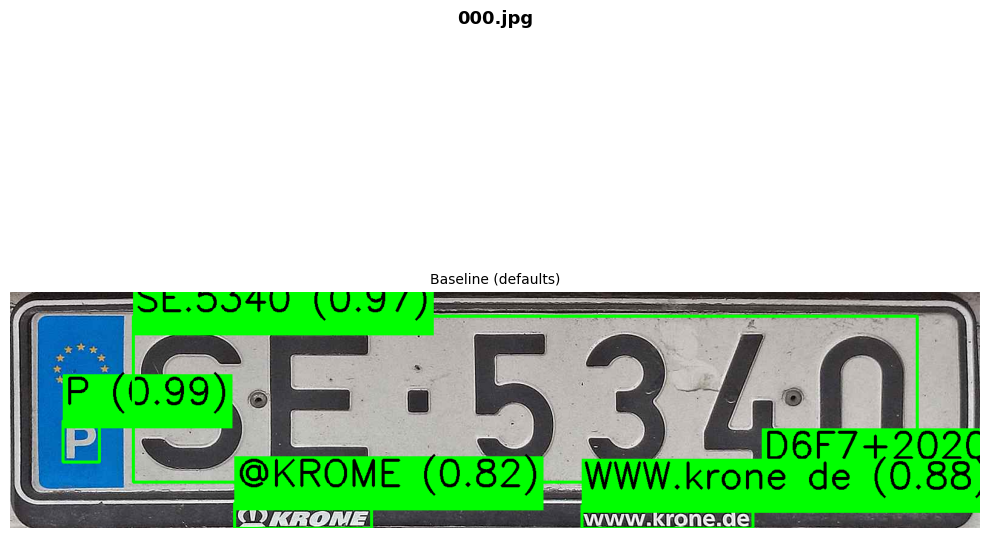

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



2543321768_47334a6fdb_b.jpg
  'NL'                            conf=1.00
  'BN-TH-56'                      conf=1.00
  '906u3o209a'                    conf=0.01


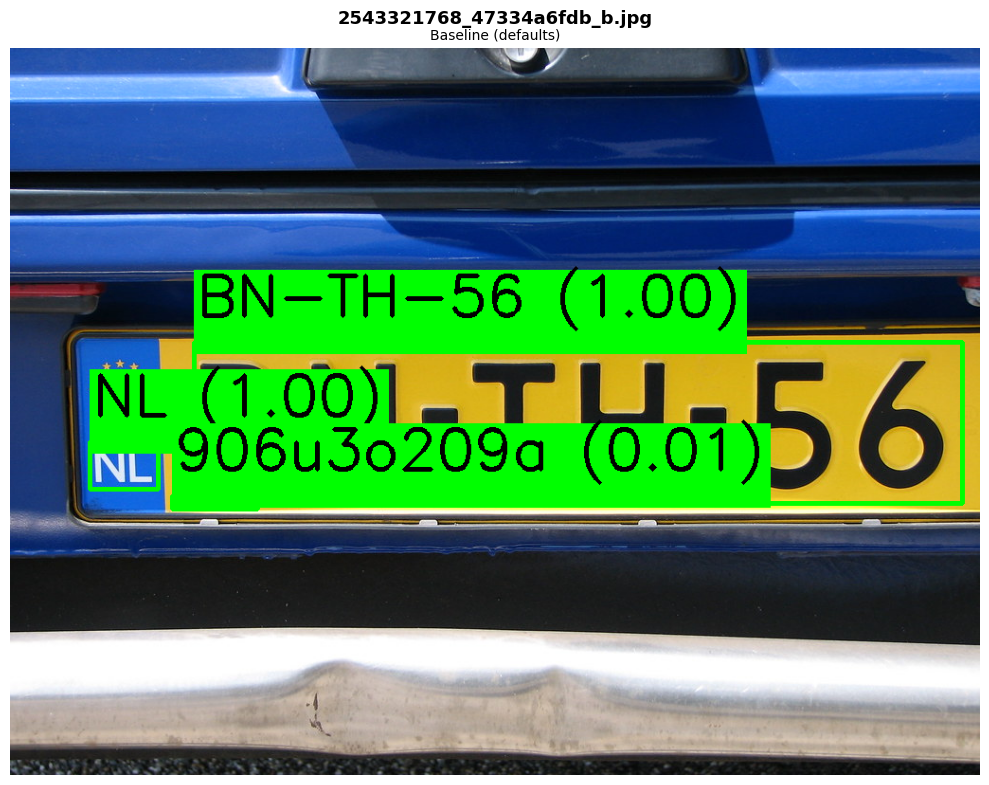

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



dsc0226.jpg
  '2SU3587'                       conf=0.97


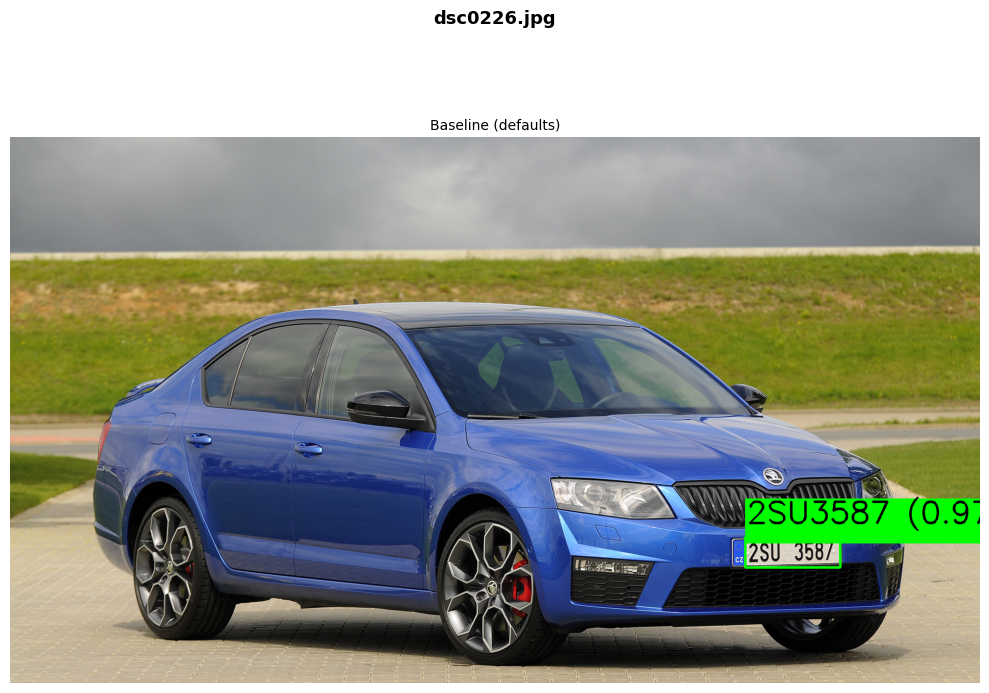

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



DSC_1939.JPG
  'Profi Liner'                   conf=0.98
  'eiro'                          conf=0.22
  'VJD-19 S'                      conf=0.48
  'TRAFIC'                        conf=0.84
  'RENAU'                         conf=0.81
  'VBK-47-B'                      conf=0.75


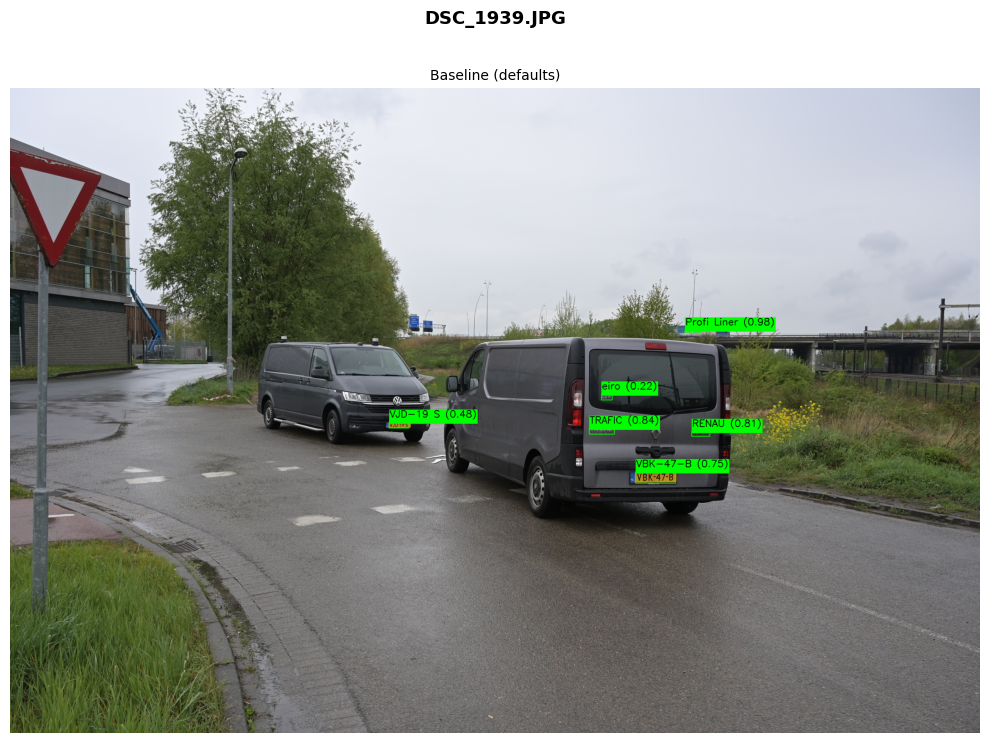

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



DSC_1940.JPG
  '45'                            conf=1.00
  'Gre'                           conf=0.87
  '0'                             conf=0.24
  'Eigen'                         conf=0.12
  'eifo'                          conf=0.37
  'Afvalbeheer'                   conf=1.00
  'Cure'                          conf=0.99
  'T5AFIC'                        conf=0.29
  'RENAUIT'                       conf=0.56
  'VBK 47-B'                      conf=0.65


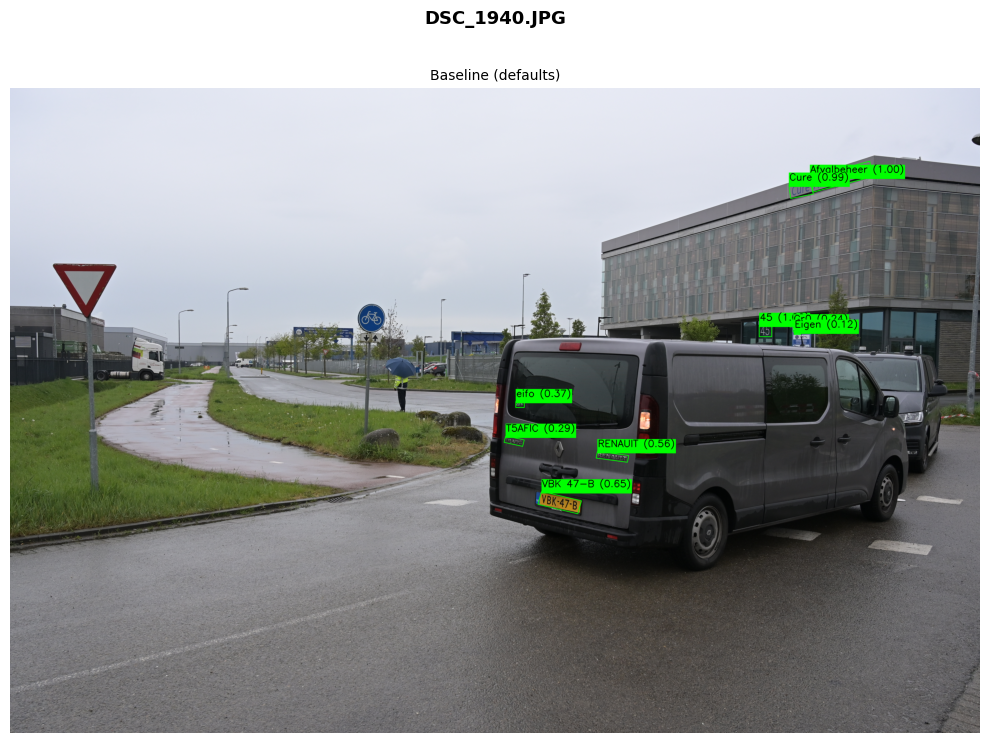

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



aaaatest.png
  'Plate crops'                   conf=0.85
  'dsc0226.jpg'                   conf=0.52
  'det 71%'                       conf=0.69
  'ocr 89%'                       conf=0.96
  'Cz'                            conf=0.83
  '2SU'                           conf=0.95
  '3587'                          conf=1.00


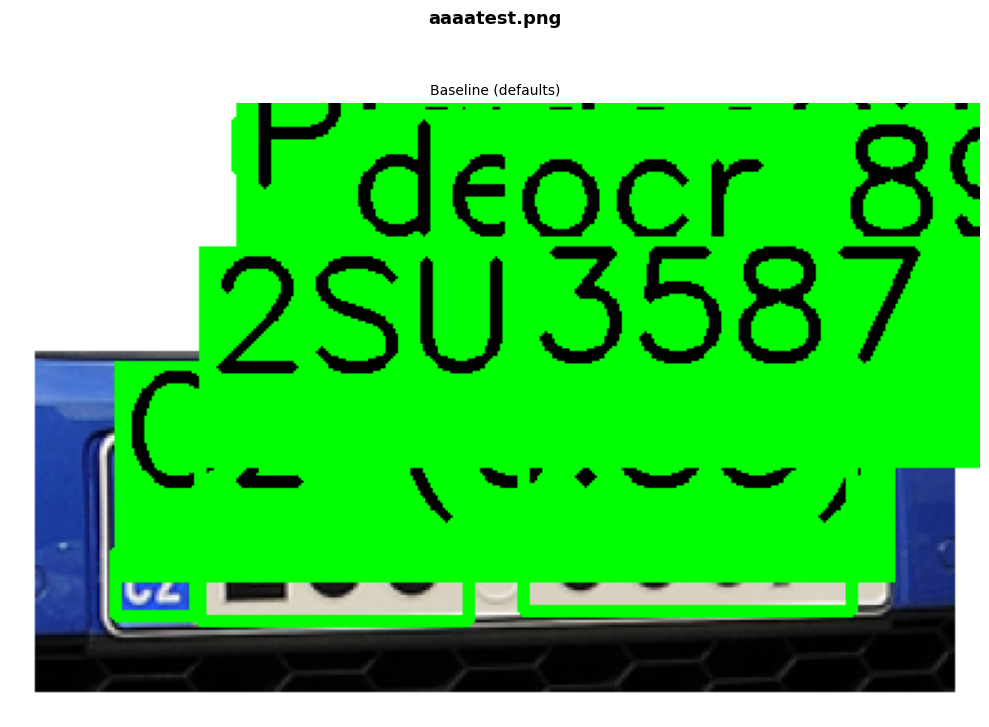

In [3]:
# Initialise reader once — reused in all cells below
reader = easyocr.Reader(['en', 'nl'], gpu=False)

for image_path in image_paths:
    image = cv2.imread(image_path)
    if image is None:
        print(f"[SKIP] {image_path}")
        continue

    ocr_results = reader.readtext(image_path)
    annotated = annotate_image(image, ocr_results)

    print(f"\n{os.path.basename(image_path)}")
    for _, text, conf in ocr_results:
        print(f"  {text!r:30s}  conf={conf:.2f}")

    show_images({"Baseline (defaults)": annotated}, title=os.path.basename(image_path))


## 4 · Parameter Reference
-> reference link:
https://www.jaided.ai/easyocr/documentation/

| Parameter | Default | What it controls |
|-----------|---------|-----------------|
| `text_threshold` | `0.7` | Minimum confidence for a region to be classified as text. **Lower → more detections, more noise.** |
| `low_text` | `0.4` | Score for low-confidence text pixels inside a region. Lower catches faint text. |
| `link_threshold` | `0.4` | How aggressively adjacent character boxes are merged into one word. |
| `mag_ratio` | `1.0` | Image magnification before detection. Higher helps with small text; slows inference. |
| `contrast_ths` | `0.1` | Images with contrast below this are pre-processed. |
| `adjust_contrast` | `0.5` | Target contrast applied to low-contrast images. |
| `width_ths` | `0.5` | Maximum gap (relative to box height) allowed when merging horizontally adjacent words. |
| `decoder` | `'greedy'` | Decoding strategy: `'greedy'`, `'beamsearch'`, or `'wordbeamsearch'`. Beam search is more accurate but slower. |
| `beamWidth` | `5` | Number of beams used when `decoder='beamsearch'`. |
| `allowlist` | `None` | Restrict recognised characters, e.g. `'ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'` for plates. |
| `paragraph` | `False` | Merge nearby results into paragraph blocks. |


## 5 · Compare: Detection Sensitivity

`text_threshold` and `low_text` control how sensitive the detector is.  
- **Strict** — fewer but higher-confidence detections  
- **Loose** — catches more text but may include false positives


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | Strict                         → 5 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | Default                        → 5 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | Loose                          → 5 region(s)


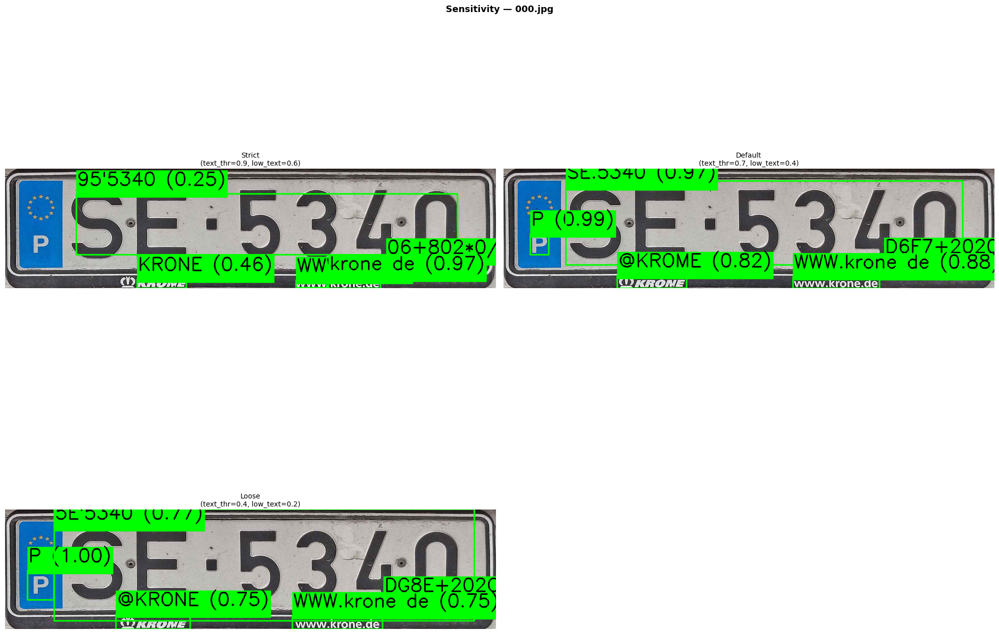

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | Strict                         → 3 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | Default                        → 3 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | Loose                          → 3 region(s)


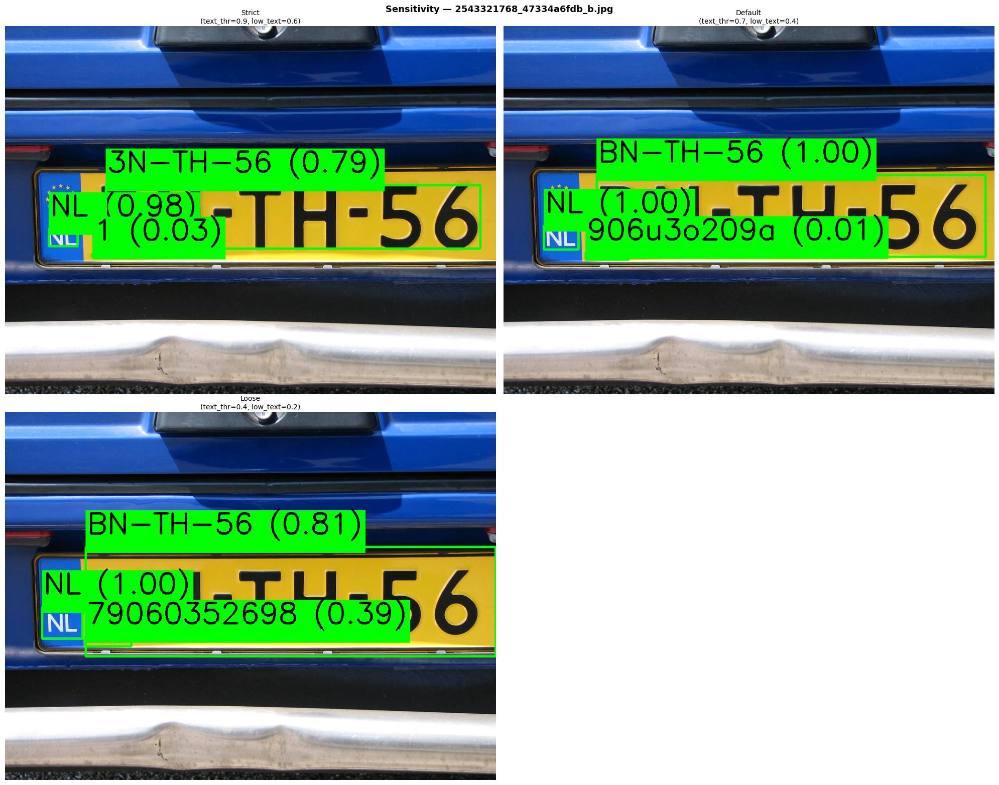

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | Strict                         → 2 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | Default                        → 1 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | Loose                          → 3 region(s)


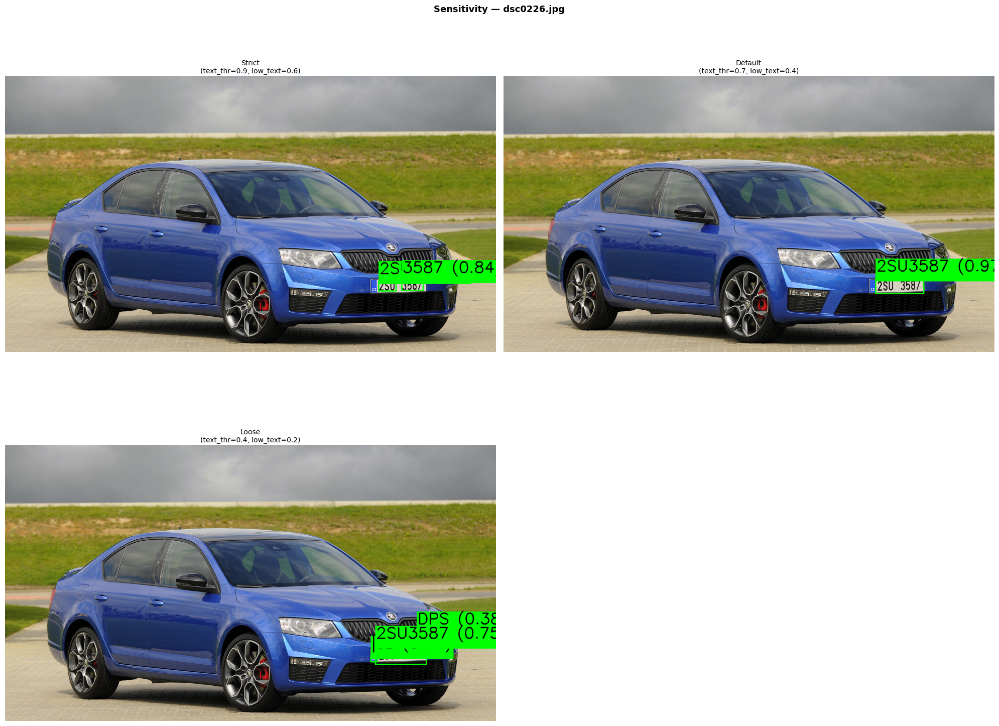

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | Strict                         → 2 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | Default                        → 6 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | Loose                          → 9 region(s)


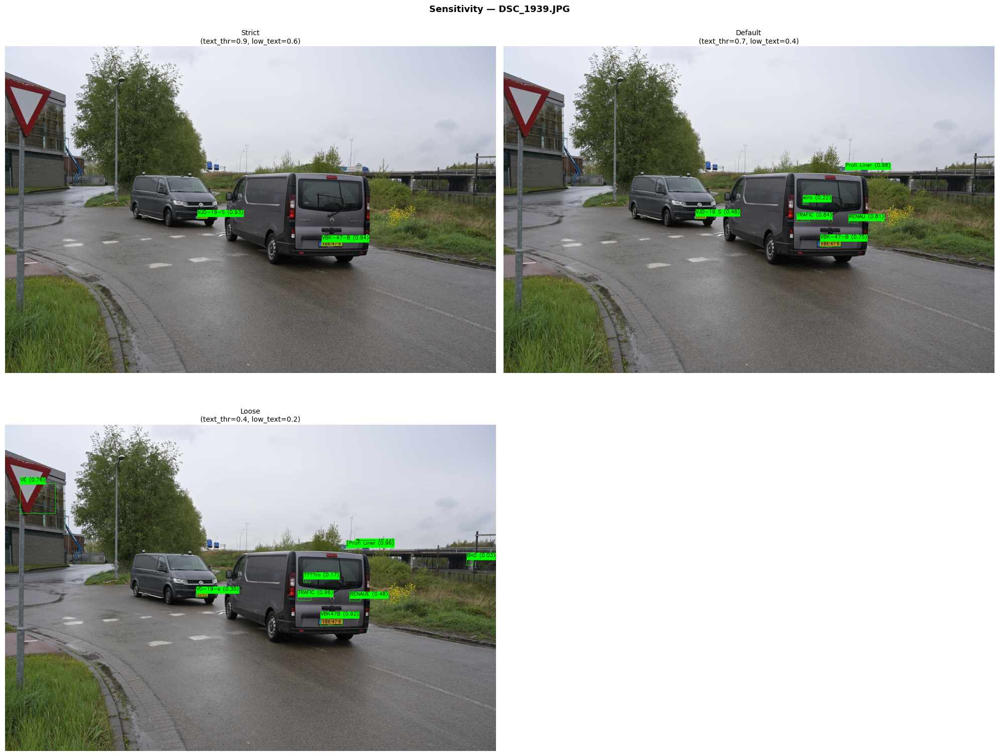

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | Strict                         → 4 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | Default                        → 10 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | Loose                          → 12 region(s)


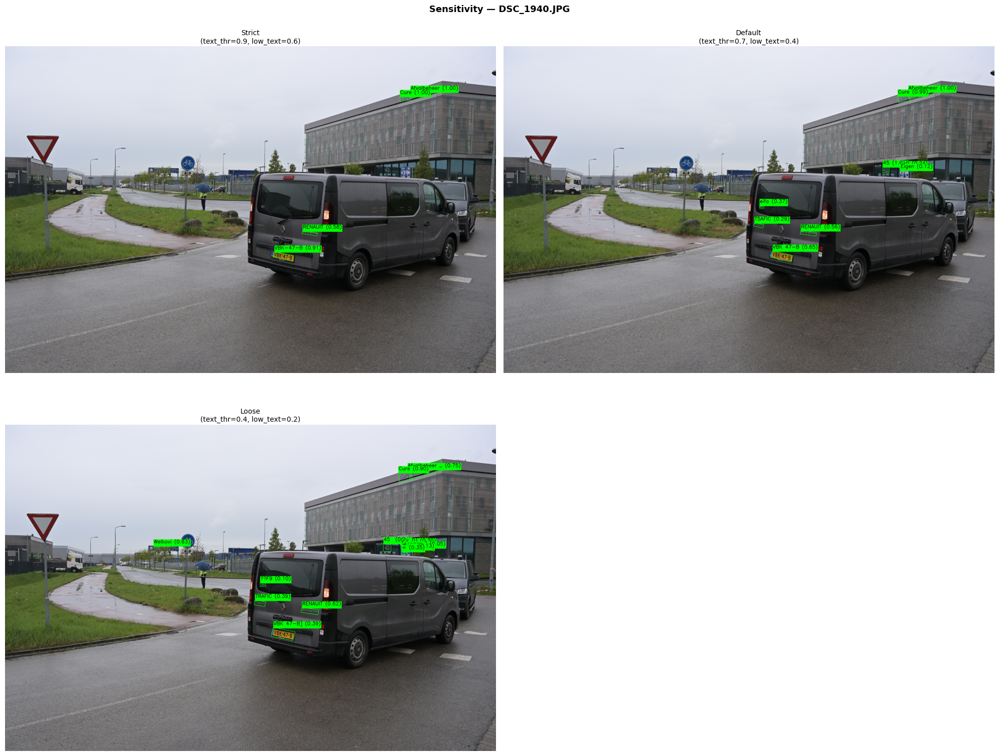

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | Strict                         → 6 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | Default                        → 7 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | Loose                          → 5 region(s)


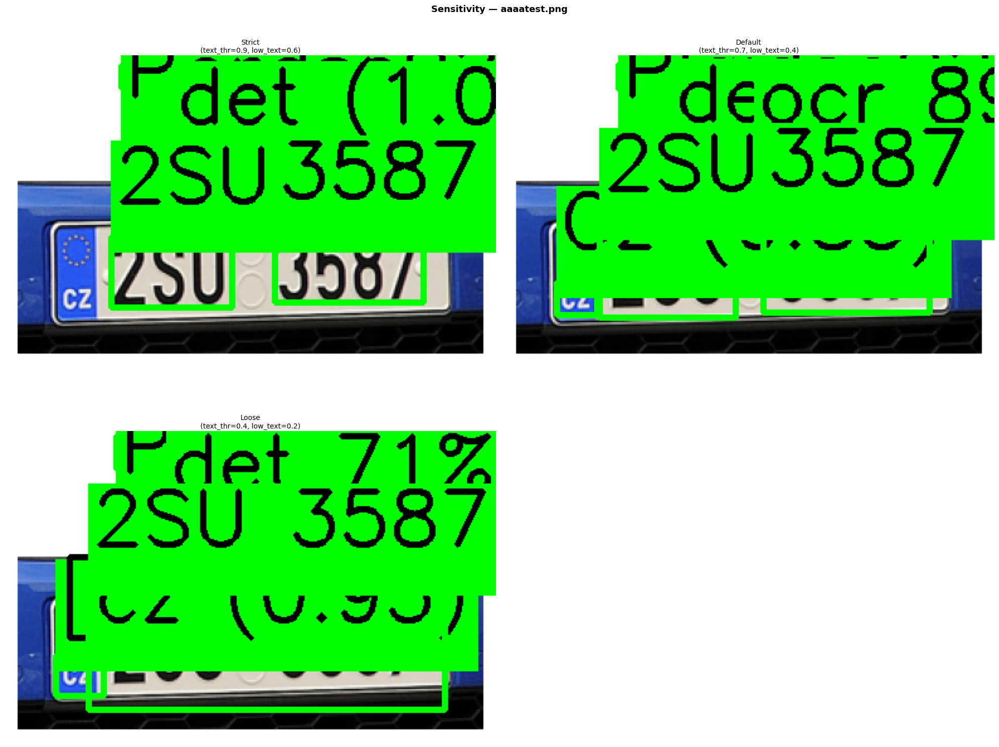

In [4]:
sensitivity_configs = {
    "Strict\n(text_thr=0.9, low_text=0.6)": dict(text_threshold=0.9, low_text=0.6),
    "Default\n(text_thr=0.7, low_text=0.4)": dict(text_threshold=0.7, low_text=0.4),
    "Loose\n(text_thr=0.4, low_text=0.2)":  dict(text_threshold=0.4, low_text=0.2),
}

for image_path in image_paths:
    image = cv2.imread(image_path)
    if image is None:
        continue

    variants = {}
    for label, params in sensitivity_configs.items():
        results = reader.readtext(image_path, **params)
        variants[label] = annotate_image(image, results)
        print(f"{os.path.basename(image_path)} | {label.splitlines()[0]:30s} → {len(results)} region(s)")

    show_images(variants, title=f"Sensitivity — {os.path.basename(image_path)}")


### Observations

#### Distanced Photos (Full Car View)

When using **high sensitivity thresholds** (`text_threshold=0.9`, `low_text=0.6`), the OCR model focused almost exclusively on **clear and well-defined text regions**. In this setup, license plates were consistently detected with high confidence, while most background noise and irrelevant text were ignored.

With **moderate (default) parameters** (`text_threshold=0.7`, `low_text=0.4`), the model began detecting **additional text regions** within the image. However, this came at a trade-off: while more text was found, the **confidence in clearly visible license plates slightly decreased**, indicating reduced precision.

At **low sensitivity thresholds** (`text_threshold=0.4`, `low_text=0.2`), the OCR became overly permissive, detecting a large number of regions. This resulted in **increased false positives and hallucinated text**, significantly lowering the overall reliability of the output.

---

#### Close-Up Photos (Zoomed License Plate)

For close-up images of license plates, the behavior differed noticeably. Using **high sensitivity thresholds** led to **hallucinations or missed detections**, suggesting the model became too restrictive even for clearly visible plate characters.

The **moderate parameter configuration** (`text_threshold=0.7`, `low_text=0.4`) produced the **most balanced and accurate results**, with strong recognition and stable confidence levels across the plate.

Lower sensitivity thresholds (`text_threshold=0.4`, `low_text=0.2`) also performed relatively well in this scenario, sometimes outperforming stricter settings, as the model remained flexible enough to capture all characters without over-restricting detection.


## 6 · Compare: Image Magnification

`mag_ratio` upscales the image before feeding it to the detector.  
Useful when text is small. Higher values slow things down but improve recall on tiny characters.


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | mag_ratio=0.5        → 6 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | mag_ratio=1.0        → 5 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | mag_ratio=1.5        → 6 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | mag_ratio=2.0        → 6 region(s)


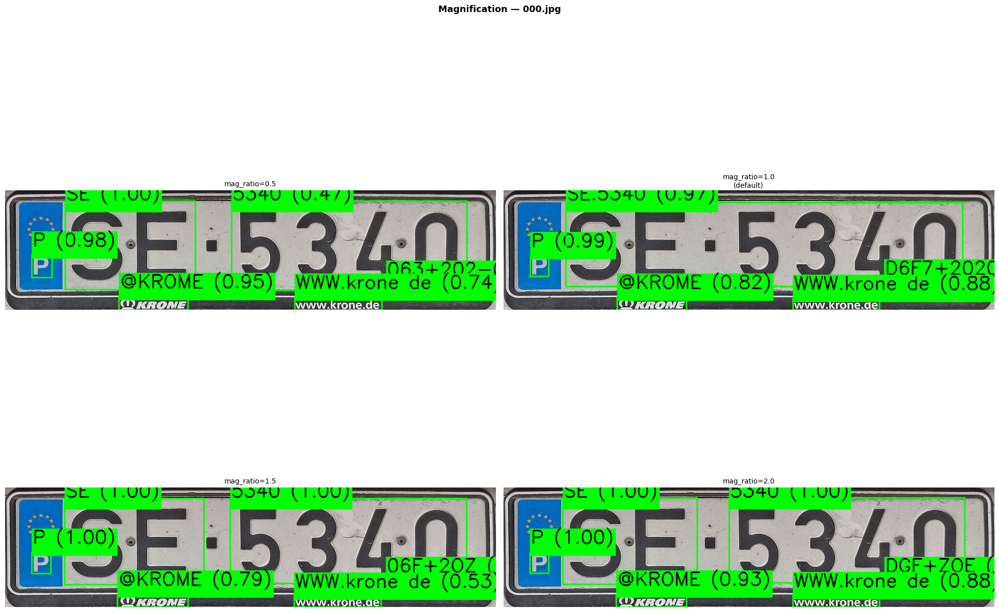

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | mag_ratio=0.5        → 2 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | mag_ratio=1.0        → 3 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | mag_ratio=1.5        → 3 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | mag_ratio=2.0        → 3 region(s)


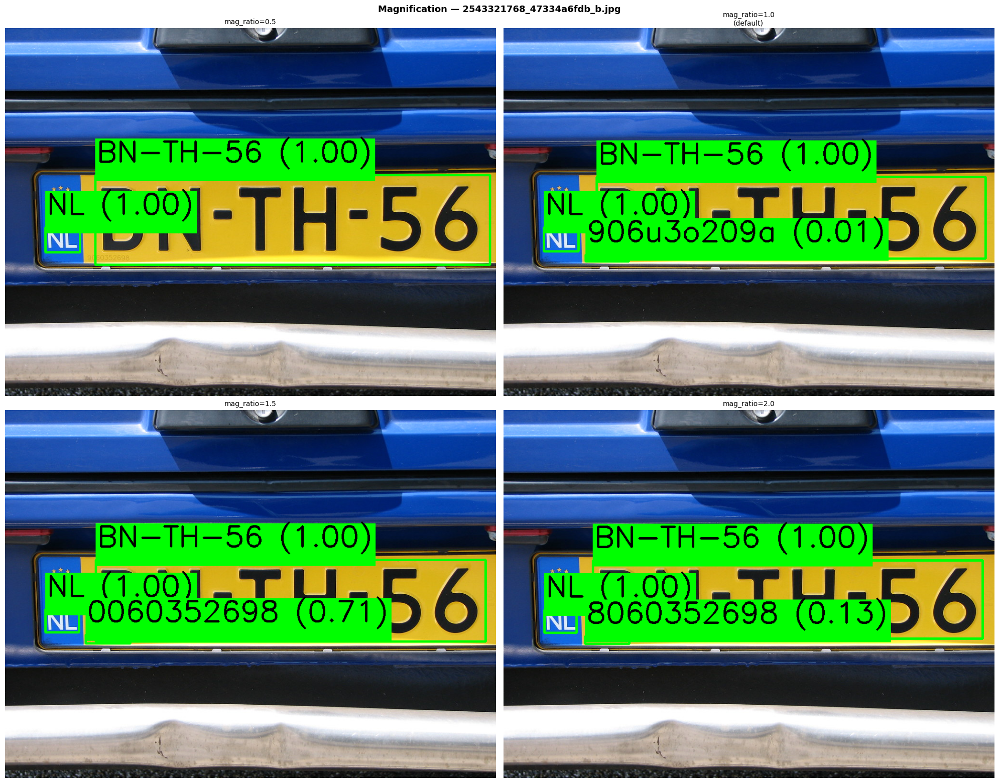

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | mag_ratio=0.5        → 1 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | mag_ratio=1.0        → 1 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | mag_ratio=1.5        → 1 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | mag_ratio=2.0        → 1 region(s)


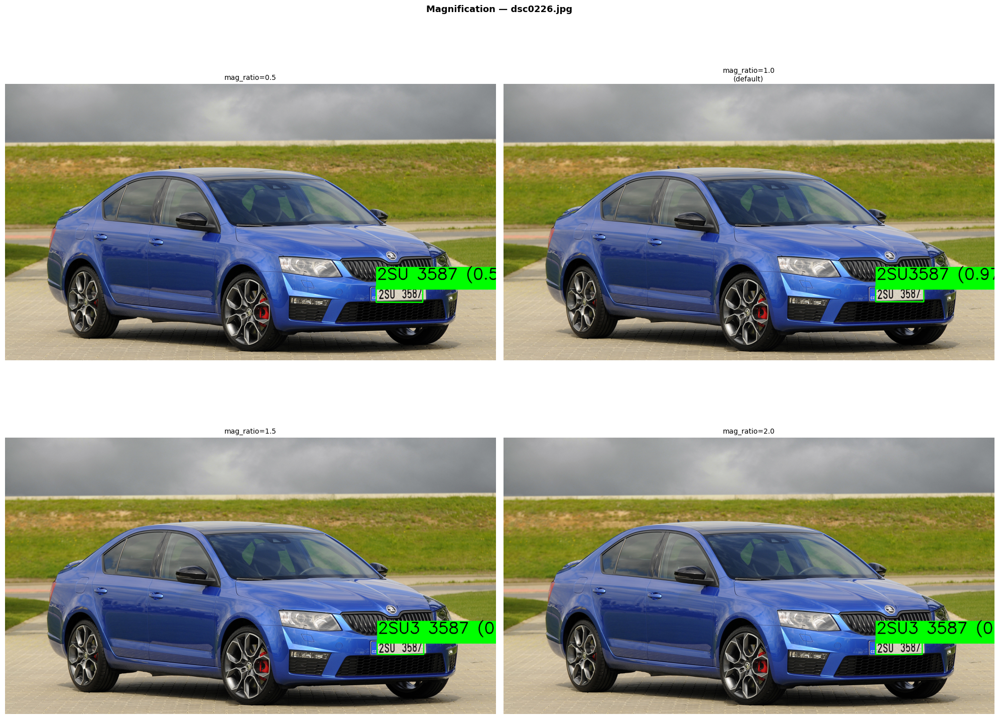

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | mag_ratio=0.5        → 6 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | mag_ratio=1.0        → 6 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | mag_ratio=1.5        → 6 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | mag_ratio=2.0        → 6 region(s)


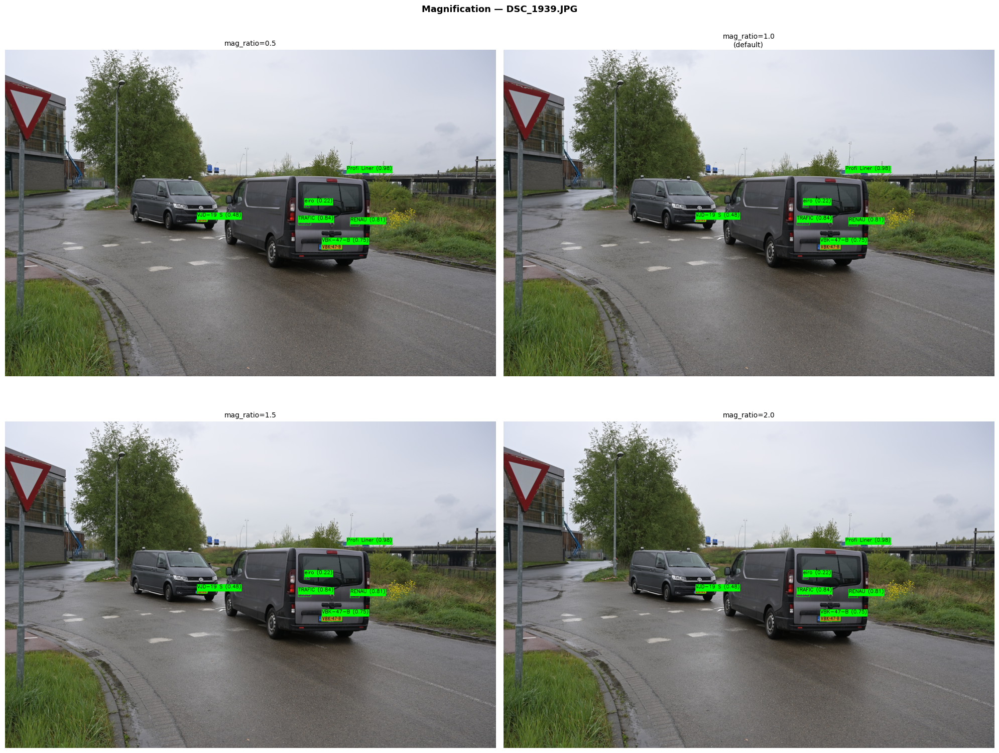

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | mag_ratio=0.5        → 10 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | mag_ratio=1.0        → 10 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | mag_ratio=1.5        → 10 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | mag_ratio=2.0        → 10 region(s)


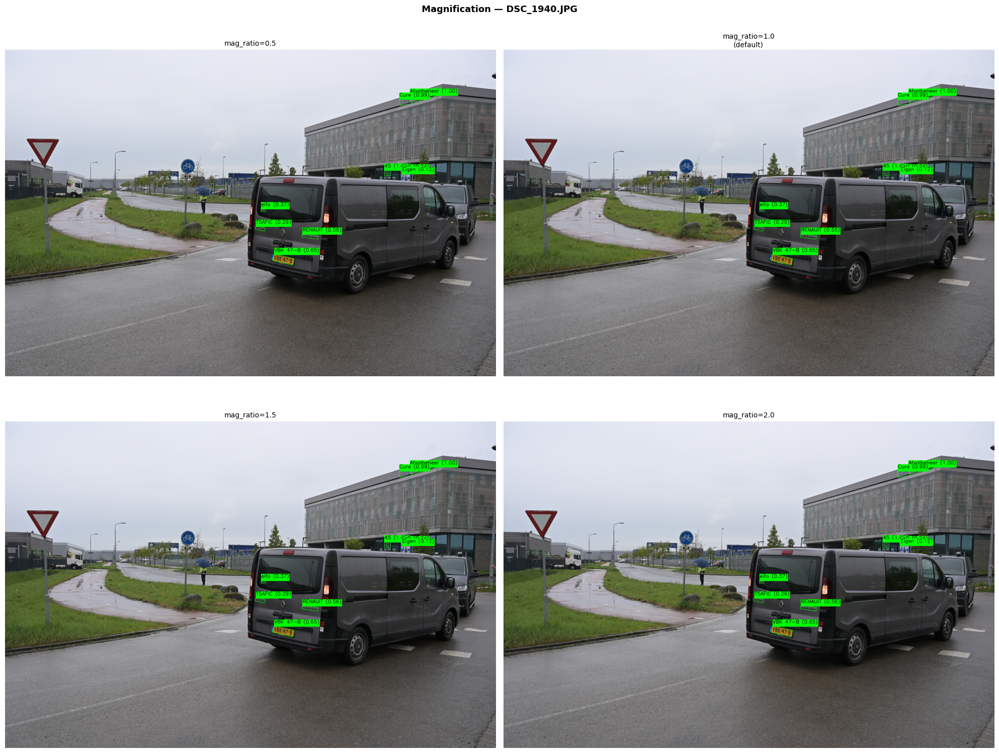

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | mag_ratio=0.5        → 5 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | mag_ratio=1.0        → 7 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | mag_ratio=1.5        → 7 region(s)


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | mag_ratio=2.0        → 8 region(s)


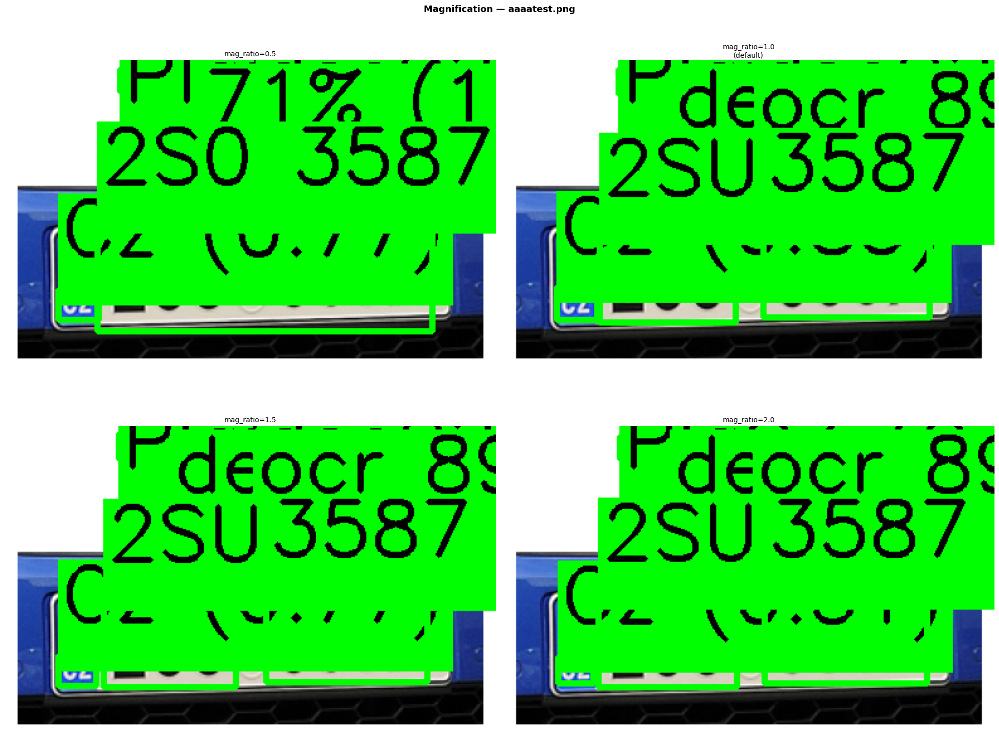

In [5]:
mag_configs = {
    "mag_ratio=0.5": dict(mag_ratio=0.5),
    "mag_ratio=1.0\n(default)": dict(mag_ratio=1.0),
    "mag_ratio=1.5": dict(mag_ratio=1.5),
    "mag_ratio=2.0": dict(mag_ratio=2.0),
}

for image_path in image_paths:
    image = cv2.imread(image_path)
    if image is None:
        continue

    variants = {}
    for label, params in mag_configs.items():
        results = reader.readtext(image_path, **params)
        variants[label] = annotate_image(image, results)
        print(f"{os.path.basename(image_path)} | {label.splitlines()[0]:20s} → {len(results)} region(s)")

    show_images(variants, title=f"Magnification — {os.path.basename(image_path)}")


### Observations

#### Distanced Photos (Full Car View)

Across all tested `mag_ratio` values, there was **no significant change** in detection performance for distanced images. The OCR results remained relatively consistent, suggesting that magnification does not play a major role when the license plate and surrounding text are already small within the overall scene.

---

#### Close-Up Photos (Zoomed License Plate)

For close-up images, especially those containing **very small or fine characters**, magnification had a noticeable impact. Using a **low magnification** (`mag_ratio=0.5`) caused the OCR to **ignore smaller characters entirely**, leading to incomplete or missing detections.

At higher values (`mag_ratio=1.5` and `mag_ratio=2.0`), the detection of smaller characters **improved significantly**, as the OCR was better able to capture fine details. These settings resulted in more complete and accurate text recognition compared to lower magnification levels.


## 7 · Compare: Decoder Strategy

The **decoder** converts the neural network's raw output into text.  
- `greedy` — fastest, picks the most likely character at each step  
- `beamsearch` — explores multiple paths simultaneously, more accurate  
- `wordbeamsearch` — like beamsearch but constrained to a word dictionary


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | greedy                    → ['P', 'SE.5340', 'D6F7+2020/s', '@KROME', 'WWW.krone de']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | beamsearch                → ['P', 'SE.5340', 'D6F7+2020/s', '@KROME', 'WWW.krone de']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | beamsearch                → ['P', 'SE.5340', 'D6F7+2020/s', '@KROME', 'WWW.krone de']


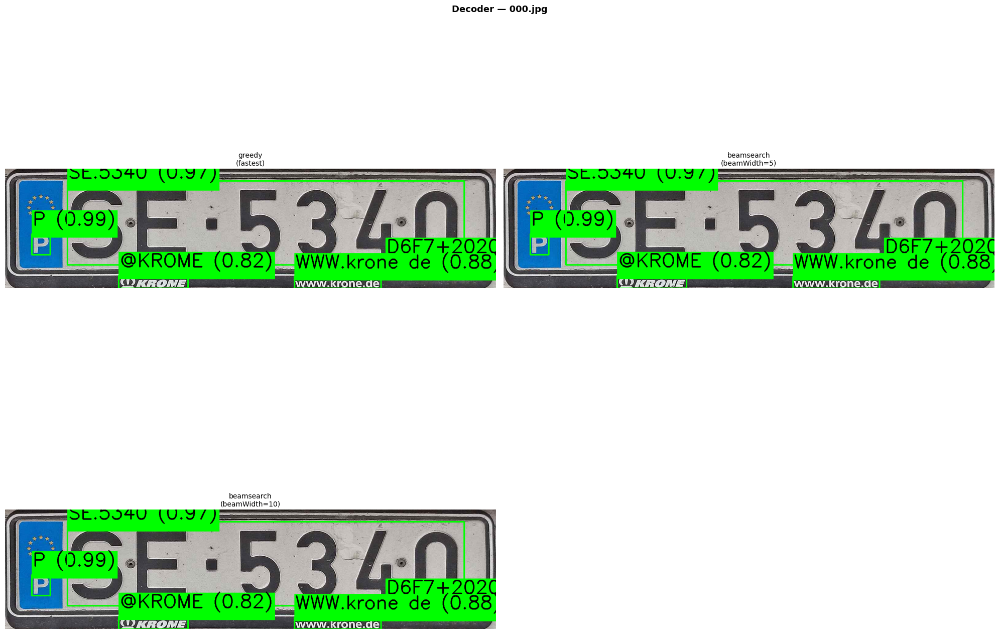

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | greedy                    → ['NL', 'BN-TH-56', '906u3o209a']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | beamsearch                → ['NL', 'BN-TH-56', '906u3o209a']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | beamsearch                → ['NL', 'BN-TH-56', '906u3o209a']


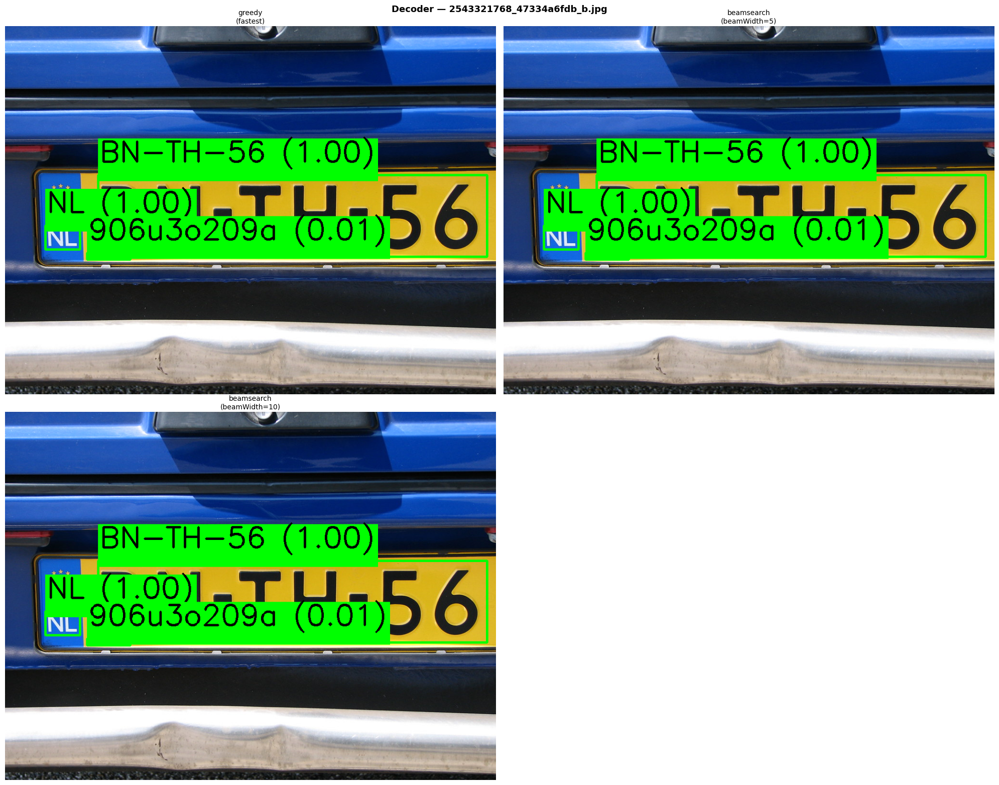

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | greedy                    → ['2SU3587']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | beamsearch                → ['2SU3587']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | beamsearch                → ['2SU3587']


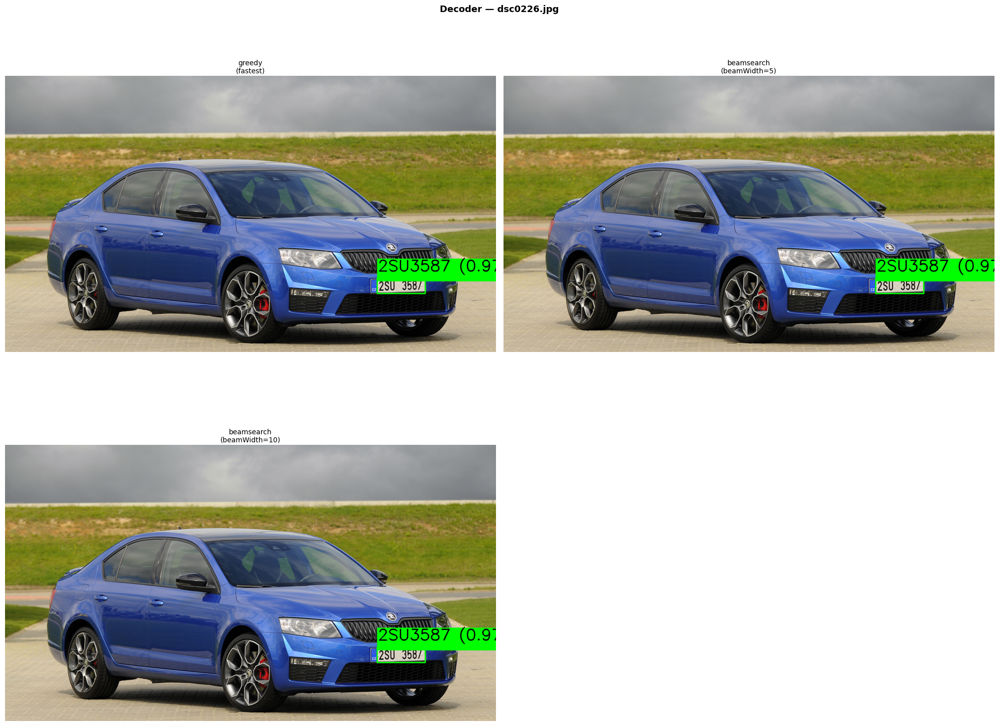

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | greedy                    → ['Profi Liner', 'eiro', 'VJD-19 S', 'TRAFIC', 'RENAU', 'VBK-47-B']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | beamsearch                → ['Profi Liner', 'eiro', 'VJD-19 S', 'TRAFIC', 'RENAU', 'VBK-47-B']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | beamsearch                → ['Profi Liner', 'eiro', 'VJD-19 S', 'TRAFIC', 'RENAU', 'VBK-47-B']


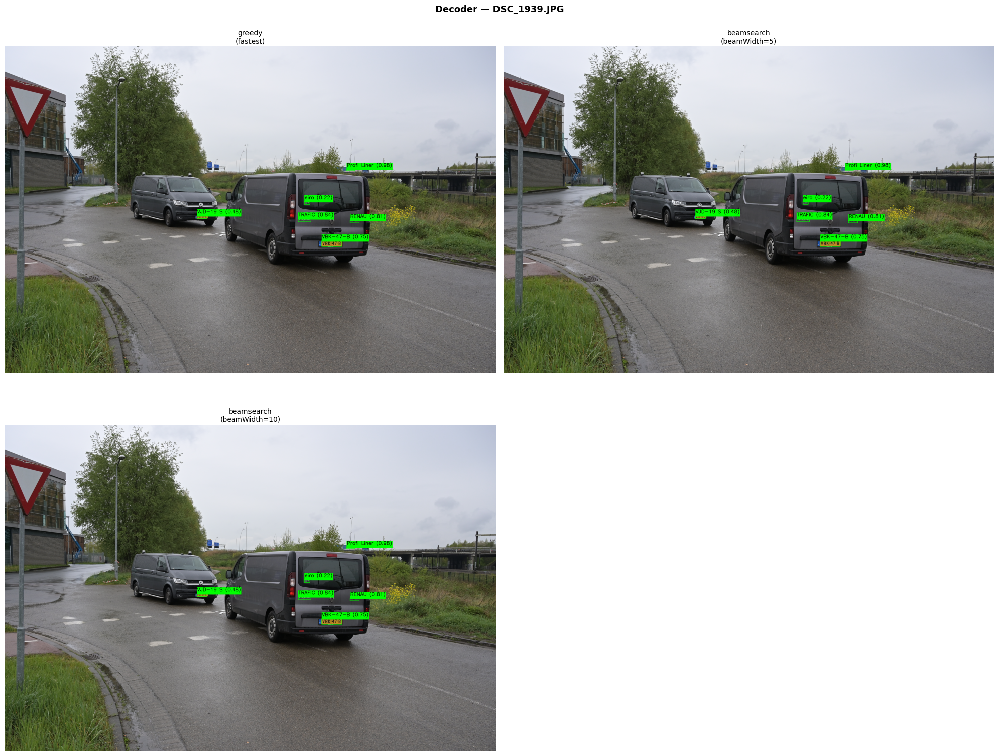

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | greedy                    → ['45', 'Gre', '0', 'Eigen', 'eifo', 'Afvalbeheer', 'Cure', 'T5AFIC', 'RENAUIT', 'VBK 47-B']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | beamsearch                → ['45', 'Gre', '0', 'Eigen', 'eifo', 'Afvalbeheer', 'Cure', 'T5AIC', 'RENAUIT', 'VBK 47-B']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | beamsearch                → ['45', 'Gre', '0', 'Eigen', 'eifo', 'Afvalbeheer', 'Cure', 'T5AIC', 'RENAUIT', 'VBK 47-B']


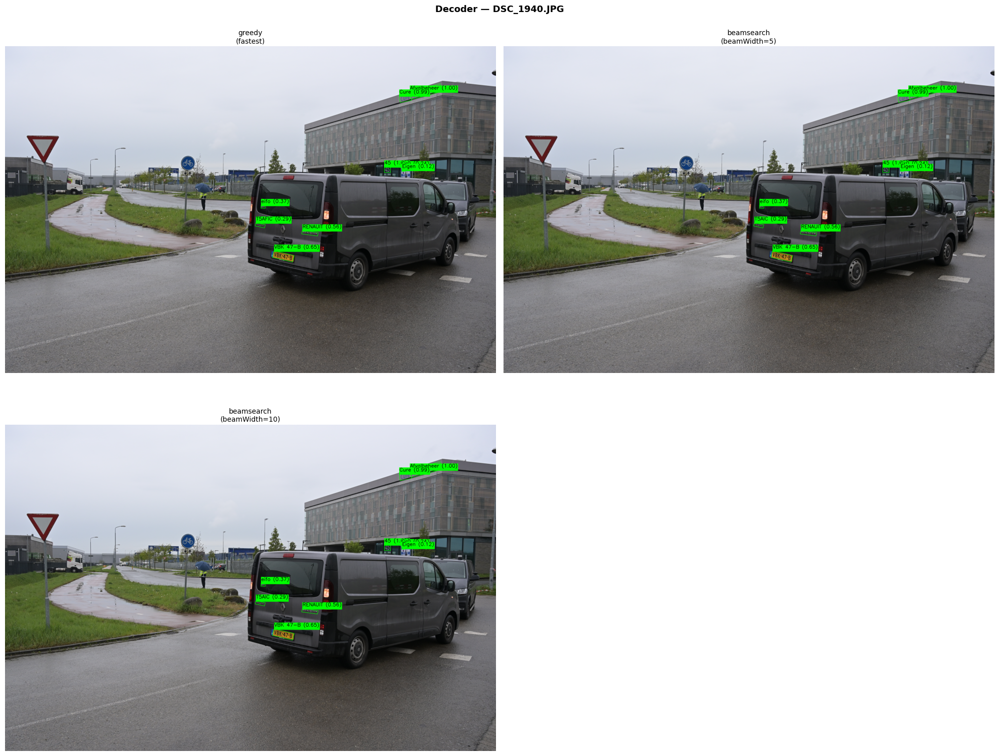

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | greedy                    → ['Plate crops', 'dsc0226.jpg', 'det 71%', 'ocr 89%', 'Cz', '2SU', '3587']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | beamsearch                → ['Plate crops', 'dsc0226.jpg', 'det 71%', 'ocr 89%', 'Cz', '2SU', '3587']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | beamsearch                → ['Plate crops', 'dsc0226.jpg', 'det 71%', 'ocr 89%', 'Cz', '2SU', '3587']


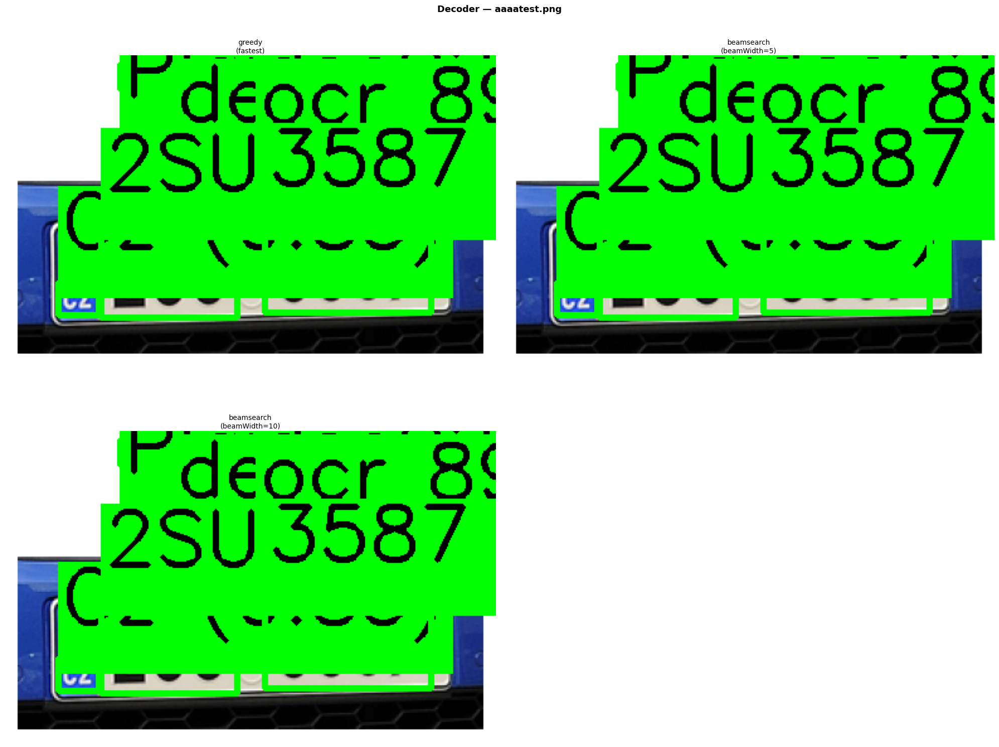

In [6]:
decoder_configs = {
    "greedy\n(fastest)":       dict(decoder="greedy"),
    "beamsearch\n(beamWidth=5)": dict(decoder="beamsearch", beamWidth=5),
    "beamsearch\n(beamWidth=10)": dict(decoder="beamsearch", beamWidth=10),
}

for image_path in image_paths:
    image = cv2.imread(image_path)
    if image is None:
        continue

    variants = {}
    for label, params in decoder_configs.items():
        results = reader.readtext(image_path, **params)
        variants[label] = annotate_image(image, results)
        texts = [t for _, t, _ in results]
        print(f"{os.path.basename(image_path)} | {label.splitlines()[0]:25s} → {texts}")

    show_images(variants, title=f"Decoder — {os.path.basename(image_path)}")


### Observation
No change detected.

## 8 · Compare: Character Allowlist

For licence plates you only expect `A-Z` and `0-9`.  
Passing an `allowlist` prevents the model from producing impossible characters like `@` or `#`, improving accuracy on constrained text.


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | No allowlist              → ['P', 'SE.5340', 'D6F7+2020/s', '@KROME', 'WWW.krone de']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg | Plate chars only          → ['P', 'SE-5340', 'D6F202-075', 'QKROME', 'WWWKROD']


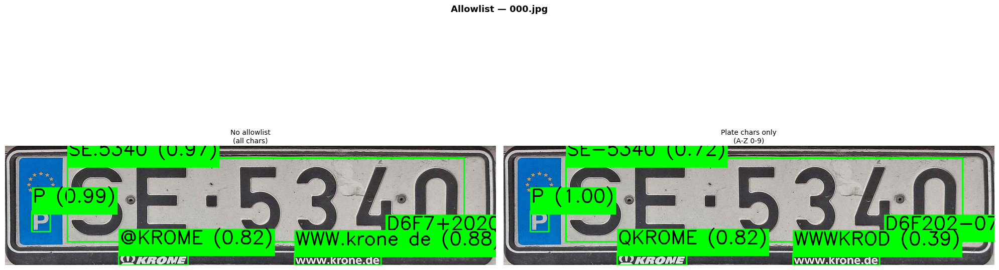

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | No allowlist              → ['NL', 'BN-TH-56', '906u3o209a']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg | Plate chars only          → ['NL', 'BN-TH-56', '9060392098']


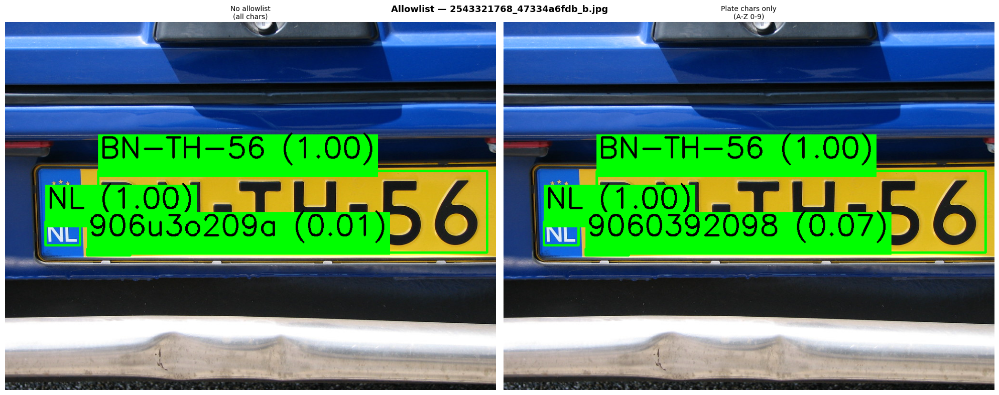

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | No allowlist              → ['2SU3587']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg | Plate chars only          → ['2SU3587']


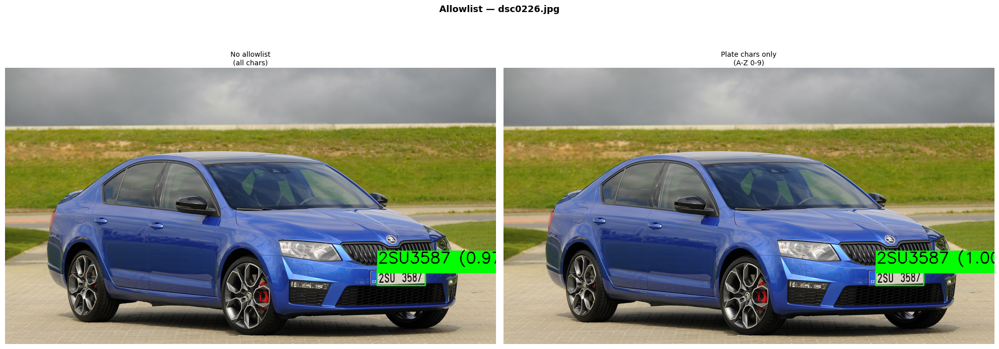

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | No allowlist              → ['Profi Liner', 'eiro', 'VJD-19 S', 'TRAFIC', 'RENAU', 'VBK-47-B']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG | Plate chars only          → ['PF0F1LI', '2F0', 'VJD-19-S', 'TRAFIC', 'RENAU', 'VBK-47-B']


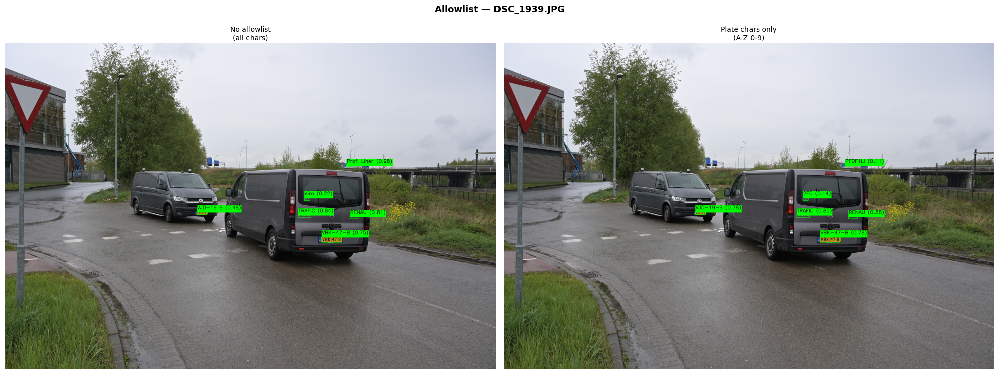

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | No allowlist              → ['45', 'Gre', '0', 'Eigen', 'eifo', 'Afvalbeheer', 'Cure', 'T5AFIC', 'RENAUIT', 'VBK 47-B']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG | Plate chars only          → ['45', 'G', '0', 'EIGEM', 'C9', 'AFVBEHEE', 'CUE', 'T5AFIC', 'RENAUIT', 'VBK-47-B']


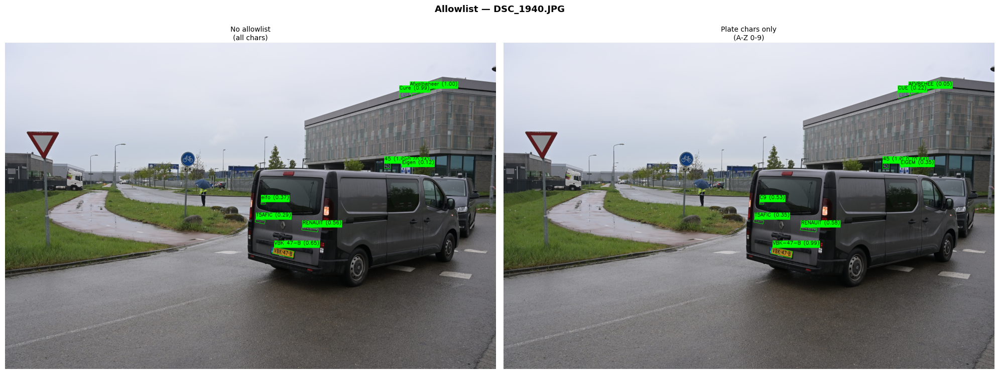

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | No allowlist              → ['Plate crops', 'dsc0226.jpg', 'det 71%', 'ocr 89%', 'Cz', '2SU', '3587']


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png | Plate chars only          → ['PIAECOPS', 'D5C0226JP9', 'DEN719', 'OCI891', 'CZ', '2SU', '3587']


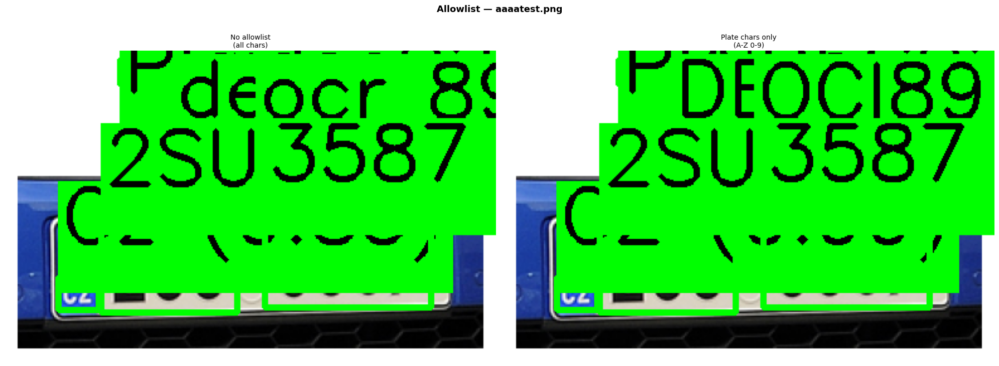

In [7]:
PLATE_CHARS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-"

allowlist_configs = {
    "No allowlist\n(all chars)":   dict(allowlist=None),
    "Plate chars only\n(A-Z 0-9)": dict(allowlist=PLATE_CHARS),
}

for image_path in image_paths:
    image = cv2.imread(image_path)
    if image is None:
        continue

    variants = {}
    for label, params in allowlist_configs.items():
        results = reader.readtext(image_path, **params)
        variants[label] = annotate_image(image, results)
        texts = [t for _, t, _ in results]
        print(f"{os.path.basename(image_path)} | {label.splitlines()[0]:25s} → {texts}")

    show_images(variants, title=f"Allowlist — {os.path.basename(image_path)}")


### Observations

#### Distanced Photos (Full Car View)

When **no allowlist** was applied (all characters allowed), the OCR detected text **accurately and consistently**, even in cases where the confidence level was relatively low. It was able to recognize both license plates and other surrounding text without strong restrictions.

When restricting the OCR to a **specific allowlist** (`A–Z`, `0–9`, `-`), the model became more specialized. This led to a **higher confidence in license plate recognition**, as the character set matched the expected format. However, this constraint negatively impacted the detection of other text in the image, where **confidence dropped and some words were misread or ignored entirely** due to the limited character set.

---

#### Close-Up Photos (Zoomed License Plate)

For close-up images, there was **no significant difference** between using an allowlist and not using one. Both configurations produced similarly accurate results, with license plate characters being recognized reliably regardless of the character restrictions.


## 9 · Best Configuration Summary

Run a chosen combination of parameters and print a clean summary table of all detected texts per image.  
Edit the `BEST_PARAMS` dict below to capture your preferred settings from the experiments above.


Image                               Text                           Confidence
------------------------------------------------------------------------------


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg                             51                                   0.11
000.jpg                             5340                                 0.57
000.jpg                             0G*20z*075                           0.08
000.jpg                             KROM                                 0.05
000.jpg                             WWW_krone de                         0.76


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\easyocr\utils.py:221: RuntimeWarning: overflow encountered in scalar add
  curr.entries[labeling].prTotal += prBlank + prNonBlank
c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\easyocr\utils.py:248: RuntimeWarning: overflow encountered in scalar add
  curr.entries[newLabeling].prNonBlank += prNonBlank


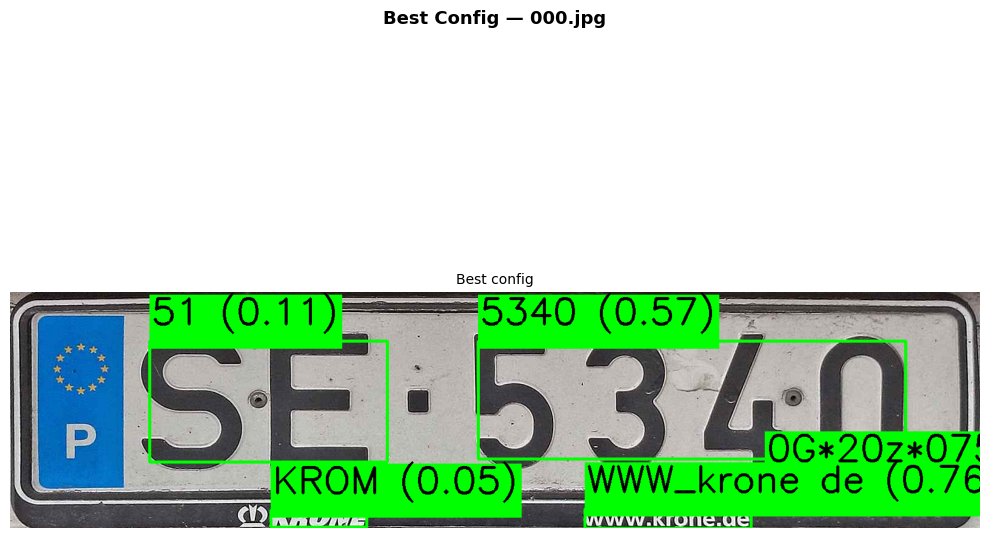

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg         NL                                   0.98
2543321768_47334a6fdb_b.jpg         3N-TH-56                             0.79
2543321768_47334a6fdb_b.jpg         4 | |                                0.11


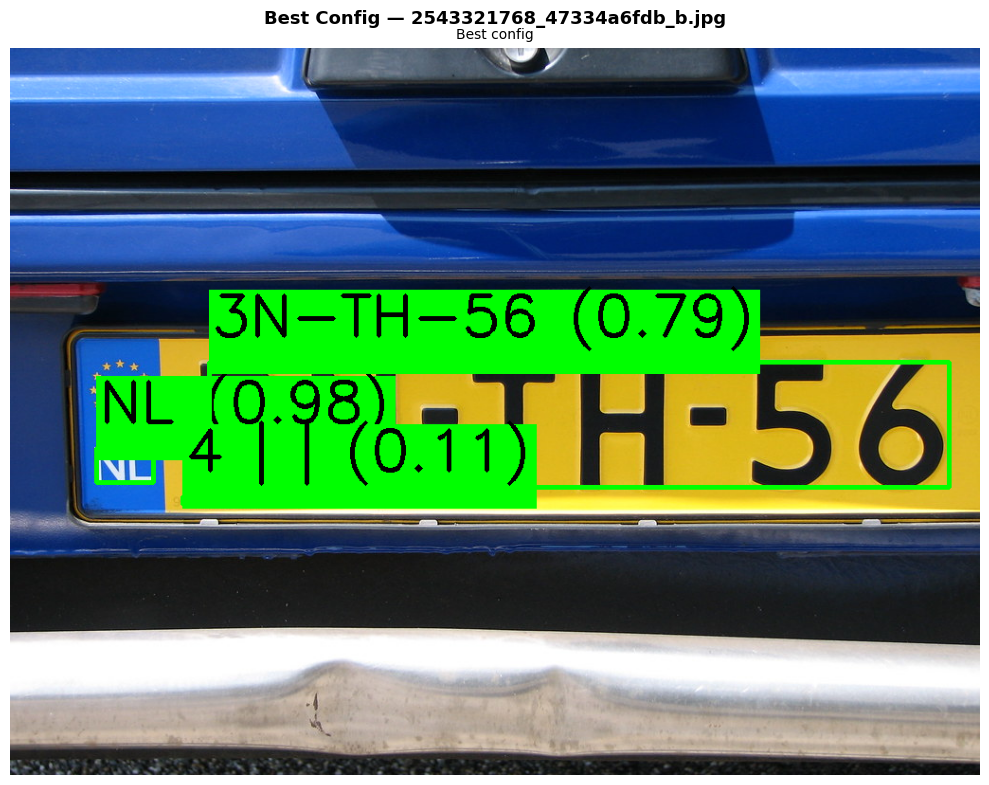

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg                         2SU                                  0.55
dsc0226.jpg                         3587                                 0.54


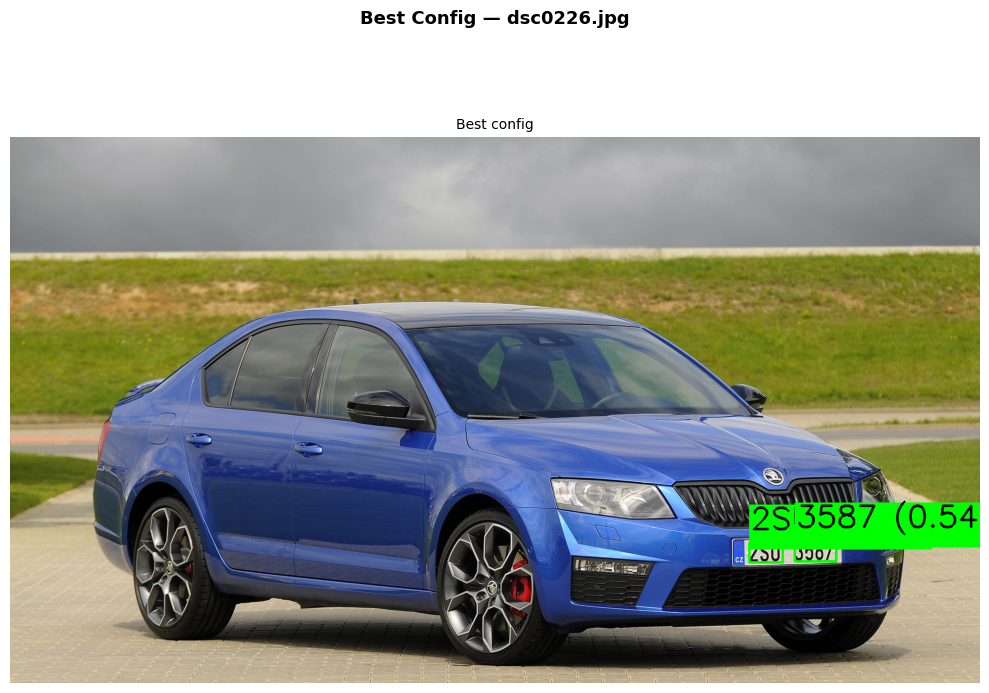

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG                        VJD-19-S                             0.93
DSC_1939.JPG                        VBK-47-B                             0.94


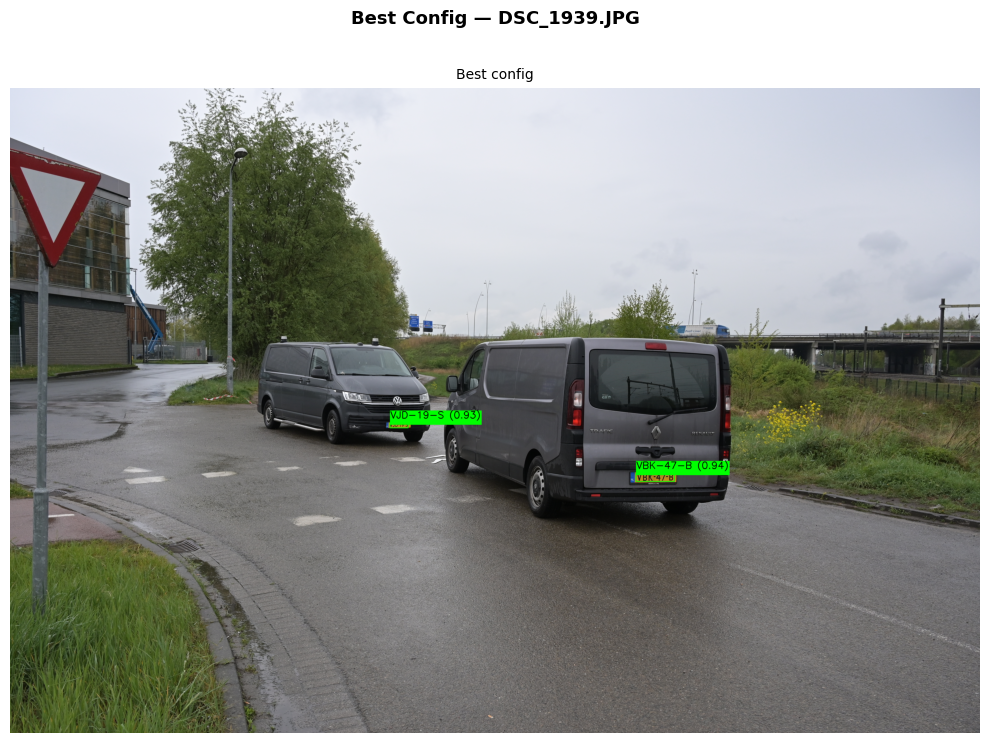

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG                        Afvalbehee                           1.00
DSC_1940.JPG                        Cure                                 1.00
DSC_1940.JPG                        RENAUIT                              0.58
DSC_1940.JPG                        VBK-47-B                             0.91


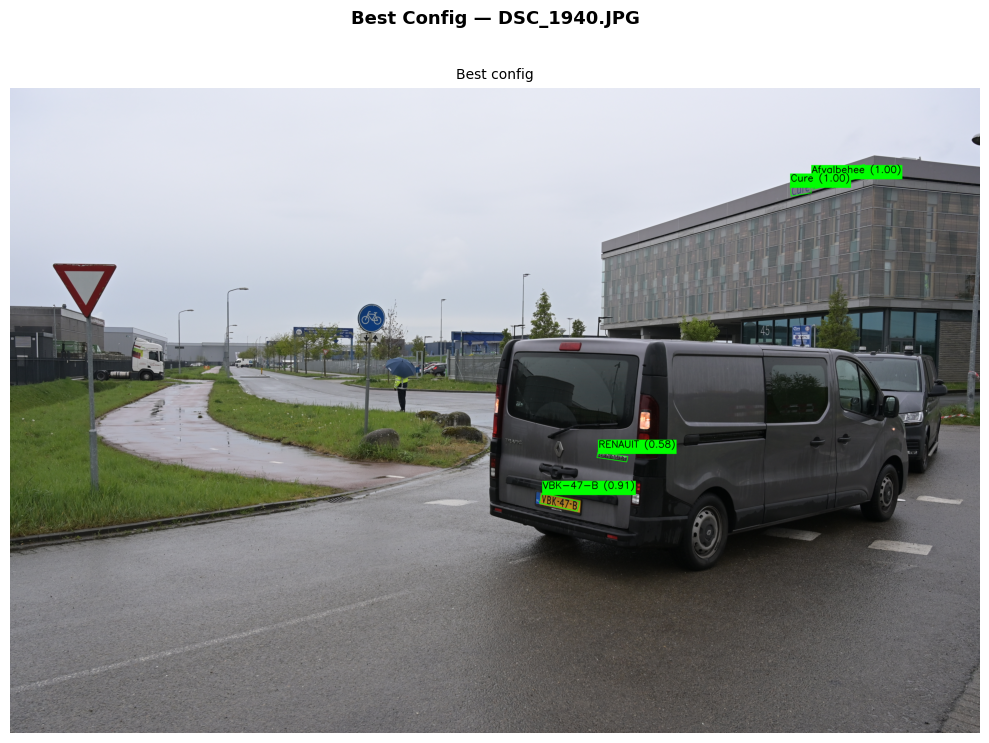

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png                        Plate crops                          1.00
aaaatest.png                        dsc0226.jpg                          0.44
aaaatest.png                        det                                  1.00
aaaatest.png                        2SU                                  0.44
aaaatest.png                        3587                                 0.57


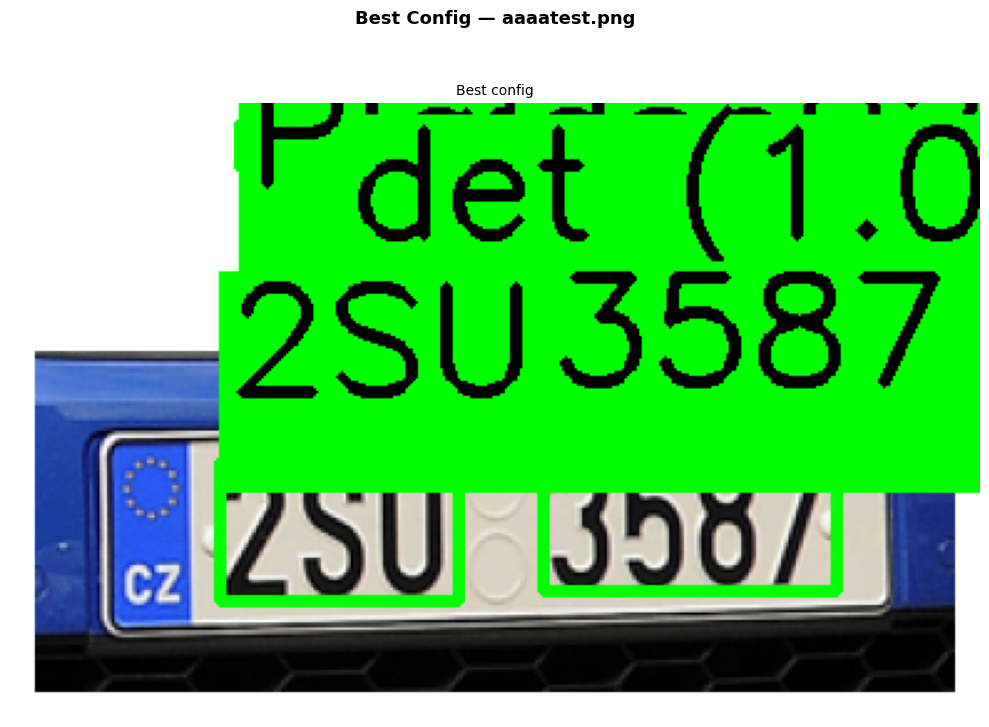

In [8]:
# ── Adjust these after reviewing sections 5-8 for Distance Photoes ─────────────────────────────────
BEST_PARAMS = dict(
    text_threshold=0.9,
    low_text=0.6,
    mag_ratio=1,
    link_threshold=0.5,
    width_ths=0.7,
    decoder='beamsearch',
    beamWidth=5,
    allowlist=None,
    paragraph=False
)

# ──────────────────────────────────────────────────────────────────────────────

print(f"{'Image':<35} {'Text':<30} {'Confidence':>10}")
print("-" * 78)

for image_path in image_paths:
    image = cv2.imread(image_path)
    if image is None:
        continue

    results = reader.readtext(image_path, **BEST_PARAMS)
    annotated = annotate_image(image, results)

    for _, text, conf in results:
        print(f"{os.path.basename(image_path):<35} {text:<30} {conf:>10.2f}")

    show_images({"Best config": annotated}, title=f"Best Config — {os.path.basename(image_path)}")


Image                               Text                           Confidence
------------------------------------------------------------------------------


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


000.jpg                             P                                    1.00
000.jpg                             SE.5340                              0.81
000.jpg                             DGF+ZOE                              0.07
000.jpg                             @KROME                               0.93
000.jpg                             WWW.krone de                         0.88


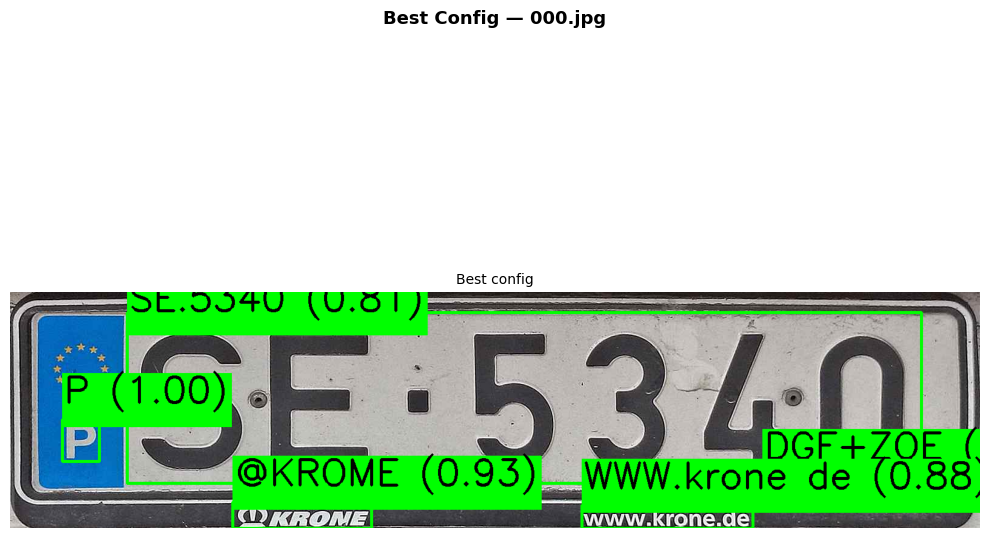

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


2543321768_47334a6fdb_b.jpg         NL                                   1.00
2543321768_47334a6fdb_b.jpg         BN-TH-56                             1.00
2543321768_47334a6fdb_b.jpg         0060362698                           0.35


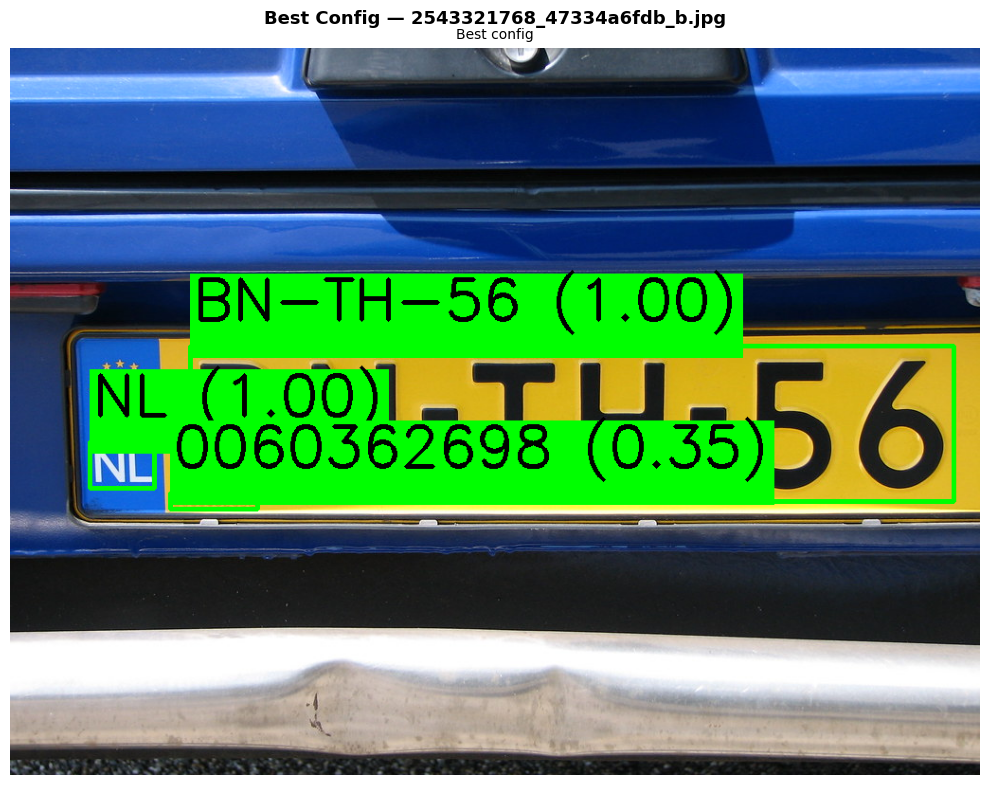

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


dsc0226.jpg                         2SU3 3587                            0.25


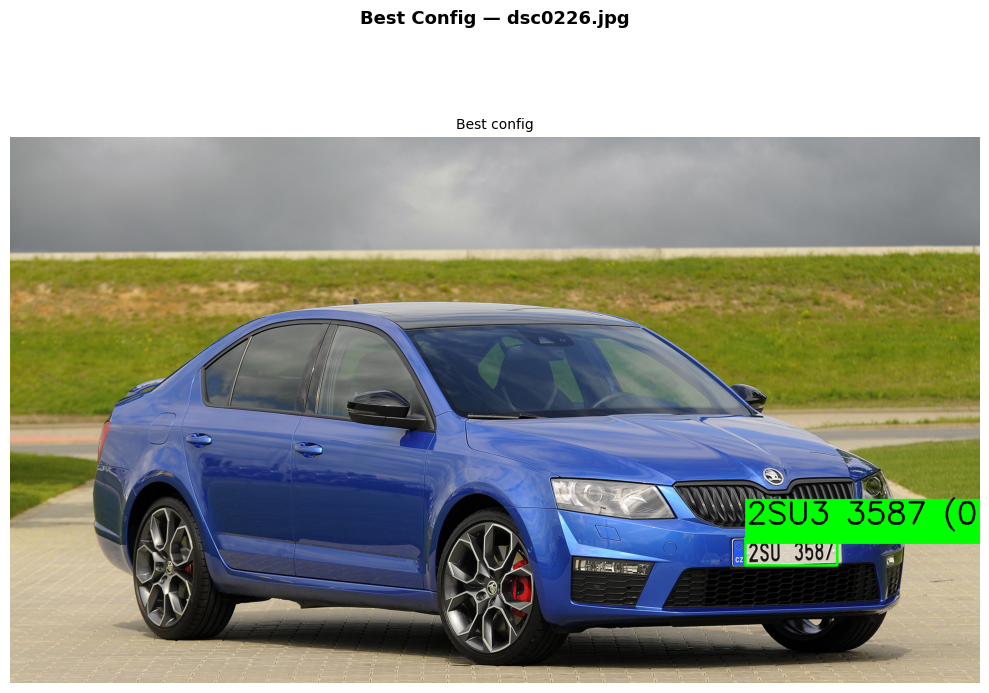

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1939.JPG                        MOnl                                 0.10
DSC_1939.JPG                        Profi Liner                          0.98
DSC_1939.JPG                        eiro                                 0.22
DSC_1939.JPG                        VJD-19 S                             0.48
DSC_1939.JPG                        TRAFIC                               0.84
DSC_1939.JPG                        RENA                                 0.96
DSC_1939.JPG                        VBK-47-B                             0.87


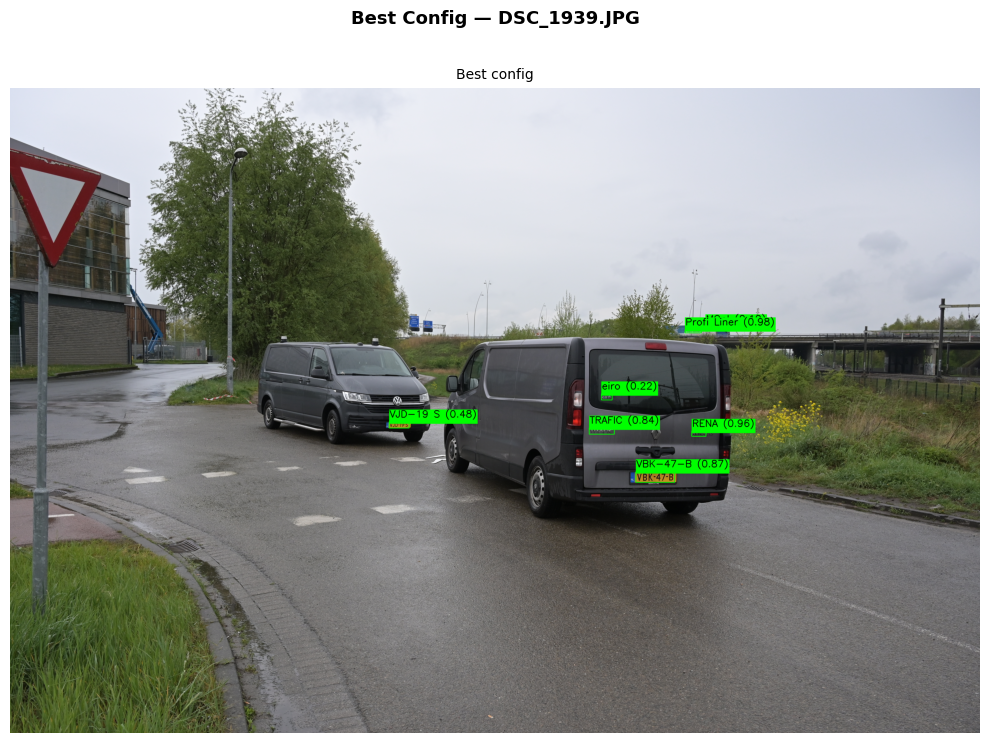

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


DSC_1940.JPG                        45                                   1.00
DSC_1940.JPG                        Gre                                  0.87
DSC_1940.JPG                        0                                    0.24
DSC_1940.JPG                        igen(earein                          0.07
DSC_1940.JPG                        6                                    0.46
DSC_1940.JPG                        eifo                                 0.37
DSC_1940.JPG                        Afvalbeheer                          1.00
DSC_1940.JPG                        Cure                                 0.99
DSC_1940.JPG                        T5AIC                                0.29
DSC_1940.JPG                        RENAUIT                              0.56
DSC_1940.JPG                        VBK 47-B                             0.65


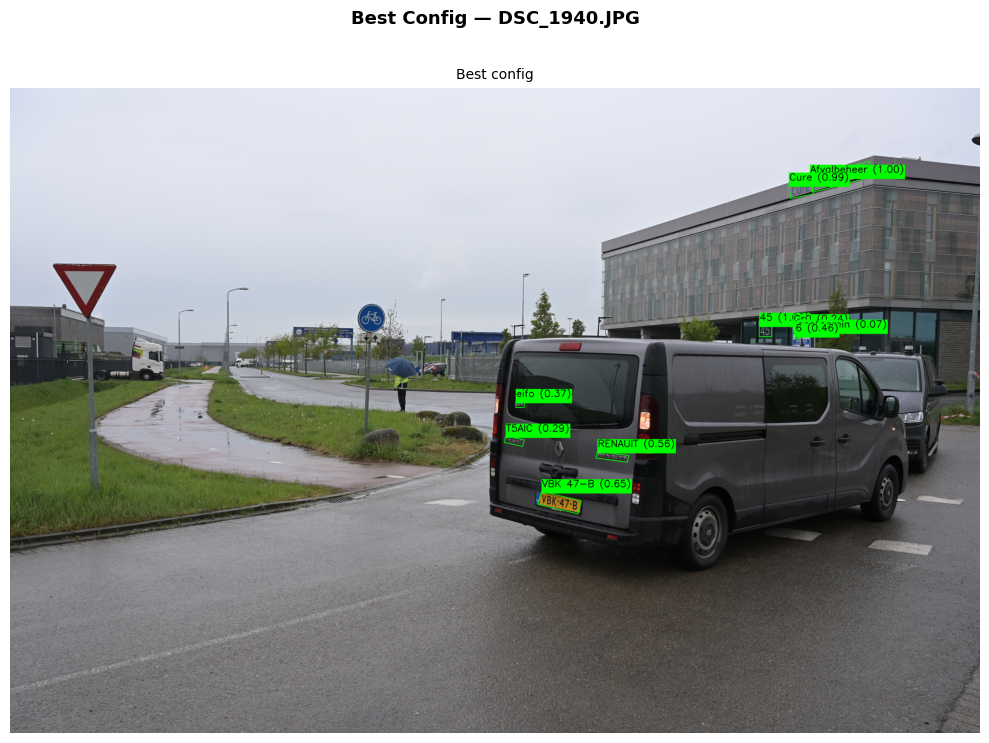

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


aaaatest.png                        Plate crops                          0.84
aaaatest.png                        dsc0226.jpg                          0.98
aaaatest.png                        CZ                                   0.88
aaaatest.png                        det 71% ocr 89%                      0.82
aaaatest.png                        [cz                                  0.61
aaaatest.png                        2SU33587                             0.33


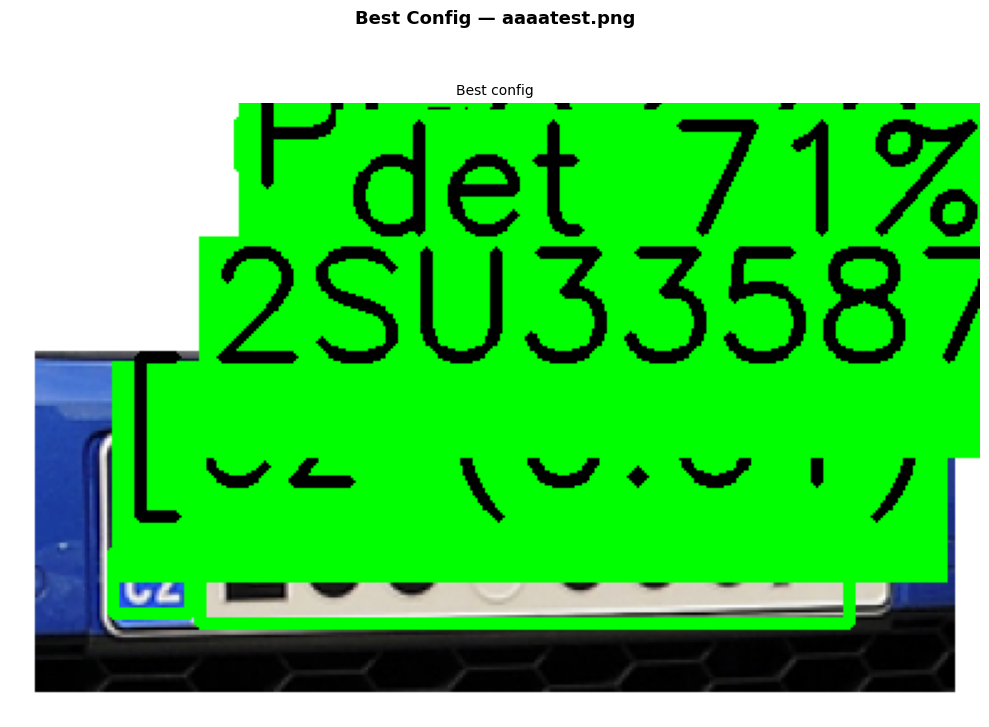

In [9]:
# ── Adjust these after reviewing sections 5-8 for Close Up Photos ─────────────────────────────────
BEST_PARAMS = dict(
    text_threshold=0.6,
    low_text=0.4,
    mag_ratio=1.8,
    link_threshold=0.5,
    width_ths=0.7,
    decoder='beamsearch',
    beamWidth=5,
    allowlist=None,
    paragraph=False
)

# ──────────────────────────────────────────────────────────────────────────────

print(f"{'Image':<35} {'Text':<30} {'Confidence':>10}")
print("-" * 78)

for image_path in image_paths:
    image = cv2.imread(image_path)
    if image is None:
        continue

    results = reader.readtext(image_path, **BEST_PARAMS)
    annotated = annotate_image(image, results)

    for _, text, conf in results:
        print(f"{os.path.basename(image_path):<35} {text:<30} {conf:>10.2f}")

    show_images({"Best config": annotated}, title=f"Best Config — {os.path.basename(image_path)}")


### Conclusion

This experiment evaluated how different OCR configuration parameters affect text detection quality, with a focus on license plate recognition in both distanced and close-up images. The analysis covered sensitivity tuning (`text_threshold`, `low_text`), character allowlisting, and image magnification (`mag_ratio`).

Overall, the results show that **no single configuration is optimal across all image types**, and performance strongly depends on image scale and text clarity.

---

### 1. Sensitivity Tuning (text thresholds)

Sensitivity settings had a clear impact on detection behavior:

* **High thresholds (strict settings)** improved precision in distanced images by focusing only on clear text, but risked missing information in more detailed or complex cases.
* **Medium thresholds (default settings)** provided the **best balance**, especially for close-up license plates, offering stable recognition and reliable confidence levels.
* **Low thresholds (loose settings)** consistently introduced **noise and hallucinated detections**, reducing overall reliability, particularly in full-image scenarios.

Key insight: **moderate sensitivity performs best as a general-purpose configuration**, while stricter settings are only beneficial in controlled, low-noise environments.

---

### 2. Allowlist Constraints

The use of an allowlist (`A–Z`, `0–9`, `-`) influenced recognition behavior in a targeted way:

* Without restrictions, OCR produced **more flexible and robust text detection**, including surrounding contextual text.
* With a strict allowlist, **license plate accuracy improved in many cases**, due to format alignment.
* However, this came at the cost of **reduced recognition quality for non-matching text**, and occasional loss of context.

Key insight: **allowlists are effective for structured data (like license plates), but reduce general text robustness**.

---

### 3. Magnification Effects

Magnification primarily impacted close-up, fine-detail scenarios:

* For **distanced images**, magnification had **minimal impact** on detection quality.
* For **close-up images with small characters**, low magnification caused **missed detections**, especially for fine details.
* Higher magnification values (`1.5–2.0`) significantly improved **small character recognition and completeness**.

Key insight: **magnification is critical for fine-grained text extraction but unnecessary for larger, already readable text regions**.

---

### Final Summary

The experiments demonstrate that OCR performance is highly dependent on context-specific tuning:

* **Moderate sensitivity settings** provide the most stable baseline.
* **Allowlists improve structured text recognition but reduce flexibility.**
* **Higher magnification improves small-text detection in close-up images.**

In practice, the best results are achieved through a **dynamic configuration strategy**, where parameters are adapted based on image distance, text size, and expected text structure rather than relying on a single global setting.
